<a href="https://colab.research.google.com/github/dr-dlr/Tesis/blob/main/Tesis_ENOE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CAPÍTULO 4. Extracción, Transformación y Carga de datos

In [1]:
# Importando librerías
import pandas as pd
import numpy as np

In [2]:
# Carga del dataset
df = pd.read_csv('/content/enoe_final.csv')
df.head()

,mpio,estrato,sexo,edad,edo_civil,pea_si_no,tipo_empleado,tipo_empresa,anios_estudio,hrs_trabajo,ingreso,emp_formal_inf,tiene_jefe
0,67,30,1,41,5,1,1,5,12,60,0,2,1.0
1,67,20,1,29,1,1,1,3,17,28,8000,2,1.0
2,67,10,2,49,1,1,1,0,3,48,0,2,1.0
3,67,20,2,33,6,1,3,2,17,40,20000,1,2.0
4,67,30,2,44,5,1,1,5,12,60,0,2,1.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1363 entries, 0 to 1362
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   mpio            1363 non-null   int64  
 1   estrato         1363 non-null   int64  
 2   sexo            1363 non-null   int64  
 3   edad            1363 non-null   int64  
 4   edo_civil       1363 non-null   int64  
 5   pea_si_no       1363 non-null   int64  
 6   tipo_empleado   1363 non-null   int64  
 7   tipo_empresa    1363 non-null   int64  
 8   anios_estudio   1363 non-null   int64  
 9   hrs_trabajo     1363 non-null   int64  
 10  ingreso         1363 non-null   int64  
 11  emp_formal_inf  1363 non-null   int64  
 12  tiene_jefe      1334 non-null   float64
dtypes: float64(1), int64(12)
memory usage: 138.6 KB


In [4]:
# Corrigiendo el tipo de 'tiene_jefe'
df['tiene_jefe'] = pd.to_numeric(df['tiene_jefe'], errors='coerce').astype('Int64')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1363 entries, 0 to 1362
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   mpio            1363 non-null   int64
 1   estrato         1363 non-null   int64
 2   sexo            1363 non-null   int64
 3   edad            1363 non-null   int64
 4   edo_civil       1363 non-null   int64
 5   pea_si_no       1363 non-null   int64
 6   tipo_empleado   1363 non-null   int64
 7   tipo_empresa    1363 non-null   int64
 8   anios_estudio   1363 non-null   int64
 9   hrs_trabajo     1363 non-null   int64
 10  ingreso         1363 non-null   int64
 11  emp_formal_inf  1363 non-null   int64
 12  tiene_jefe      1334 non-null   Int64
dtypes: Int64(1), int64(12)
memory usage: 139.9 KB


In [6]:
#Revisando valores nulos en el dataset
df.isnull().sum()

,0
mpio,0
estrato,0
sexo,0
edad,0
edo_civil,0
pea_si_no,0
tipo_empleado,0
tipo_empresa,0
anios_estudio,0
hrs_trabajo,0


In [7]:
# Llenando los nulos con de acuerdo con este criterio "Asalariados = tiene jefe", "Patrón o autoempleo = no tiene jefe" y "Desempleado = NA"
def imputar_jefe(row):
    if row['tipo_empleado'] == 0:  # Desempleado
        return 0  # No aplica
    elif row['tipo_empleado'] in [2, 3]:  # Patrón o Cuenta Propia
        return 2  # No tiene jefe
    elif row['tipo_empleado'] == 1:  # Asalariado
        return 1  # Sí tiene jefe
    return row['tiene_jefe']


df['tiene_jefe'] = df.apply(imputar_jefe, axis=1).astype('int64')

In [8]:
# Revisando que no existen nulos
df.isnull().sum()

,0
mpio,0
estrato,0
sexo,0
edad,0
edo_civil,0
pea_si_no,0
tipo_empleado,0
tipo_empresa,0
anios_estudio,0
hrs_trabajo,0


In [9]:
# Verificando valores atípicos en la variable de años de estudio
df['anios_estudio'].unique()

array([12, 17,  3,  9,  6, 16, 19,  5,  8, 10,  4, 15, 18,  0,  2, 11, 20,
       99, 21, 14,  1, 13,  7])

In [10]:
# Manejo del atípico con el promedio de años de estudio
# Cálculo del promedio de años de las personas que NO tienen 99
promedio_real = df[df['anios_estudio'] != 99]['anios_estudio'].mean()

# Redondeo del promedio porque no existen "11.82 años"
promedio_redondeado = round(promedio_real)

# Reemplazo del 99 con el valor redondeado
df.loc[df['anios_estudio'] == 99, 'anios_estudio'] = promedio_redondeado

In [11]:
df['anios_estudio'].unique()

array([12, 17,  3,  9,  6, 16, 19,  5,  8, 10,  4, 15, 18,  0,  2, 11, 20,
       21, 14,  1, 13,  7])

In [12]:
# Depuración de variables de filtrado y sin uso para el análisis
df = df.drop(columns=['mpio', 'estrato'], axis = 1)

#Población económicamente activa no se elimina porque se usará para discriminar entre población formal e informal en el EDA

In [13]:
df.columns

Index(['sexo', 'edad', 'edo_civil', 'pea_si_no', 'tipo_empleado',
       'tipo_empresa', 'anios_estudio', 'hrs_trabajo', 'ingreso',
       'emp_formal_inf', 'tiene_jefe'],
      dtype='object')

In [14]:
# Filtrando el dataframe para conservar solo ingresos mayores a 0
df = df[df['ingreso'] > 0]

print(f"Registros restantes después del filtrado: {len(df)}")
print("Verificación de valores mínimos en ingreso:")
display(df['ingreso'].describe())
display(df.head())

Registros restantes después del filtrado: 772
Verificación de valores mínimos en ingreso:


,ingreso
count,772.000000
mean,9250.195596
std,6517.308468
min,129.000000
25%,4375.000000
50%,8550.000000
75%,12650.000000
max,55000.000000


,sexo,edad,edo_civil,pea_si_no,tipo_empleado,tipo_empresa,anios_estudio,hrs_trabajo,ingreso,emp_formal_inf,tiene_jefe
1,1,29,1,1,1,3,17,28,8000,2,1
3,2,33,6,1,3,2,17,40,20000,1,2
7,1,55,5,1,1,5,6,48,8600,2,1
8,2,43,5,1,1,8,9,12,7740,1,1
9,1,70,5,1,1,4,12,72,10320,1,1


In [15]:
df.to_csv('enoe_def_clean.csv', index = False)

## Importante:

Todas las variables son objetos de tipo entero, no se convirtieron las varaiables categóricas porque se usará el diccionario de datos de la ENOE para interpretar los valores, estos aparecerán con sus respectivas etiquetas en el análisis exploratorio de datos.

In [16]:
import pandas as pd
from IPython.display import display, Markdown

promedio_general = df['ingreso'].mean()
promedio_formal = df[df['emp_formal_inf'] == 2]['ingreso'].mean()
promedio_informal = df[df['emp_formal_inf'] == 1]['ingreso'].mean()

print(f'El promedio general de la PEA es de {promedio_general.round(0)}')
print(f'El promedio general de la PEA en sector formal es de {promedio_formal.round(0)}')
print(f'El promedio general de la PEA en sector informal es de {promedio_informal.round(0)}')

El promedio general de la PEA es de 9250.0
El promedio general de la PEA en sector formal es de 13116.0
El promedio general de la PEA en sector informal es de 6886.0


# CAPÍTULO 5. ANÁLISIS EXPLORATORIO DE DATOS

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
import os

# Configuración estética para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12, 'figure.dpi': 300})

# Crear directorio para guardar figuras si no existe
if not os.path.exists('figuras_eda'):
    os.makedirs('figuras_eda')

# Diccionarios de mapeo para variables categóricas
map_sexo = {1: "Hombre", 2: "Mujer"}
map_estrato = {10: "Estrato bajo", 20: "Estrato medio bajo", 30: "Estrato medio alto", 40: "Estrato alto"}
map_edo_civil = {1: "Vive con su pareja", 2: "Está separado", 3: "Está divorciado", 4: "Está viudo", 5: "Está casado", 6: "Está soltero"}
map_pea = {1: "Población económicamente activa", 0: "Población no económicamente activa"}
map_tipo_empleado = {0: "No aplica", 1: "Subordinados y remunerados", 2: "Empleadores", 3: "Trabajadores por cuenta propia"}
map_tipo_empresa = {0: "No aplica", 1: "Micronegocios", 2: "Sin establecimientos", 3: "Con establecimientos", 4: "Pequeños establecimientos", 5: "Medianos establecimientos", 6: "Grandes establecimientos", 7: "Gobierno", 8: "Otros"}
map_emp_formal_inf = {0: "No aplica", 1: "Empleo informal", 2: "Empleo formal"}
map_tiene_jefe = {1: "Tiene un jefe o superior", 2: "No tiene un jefe o superior"}
map_target = {0: "Precariedad", 1: "Competitivo"}

## Auditoría y preparación del dataset

In [18]:
try:
    df = pd.read_csv('enoe_def_clean.csv')
    print("Dataset cargado correctamente.")
except FileNotFoundError:
    print("Error: El archivo 'enoe_final.csv' no se encuentra. Asegúrate de haberlo subido al entorno.")
    # Crear un DataFrame dummy temporal solo para que el código no falle (eliminar en uso real)
    print("Generando datos simulados para permitir la ejecución de prueba...")
    np.random.seed(42)
    df = pd.DataFrame({
        'mpio': [67]*1363,
        'estrato': np.random.choice([10,20,30,40], 1363),
        'sexo': np.random.choice([1, 2], 1363),
        'edad': np.random.randint(18, 80, 1363),
        'edo_civil': np.random.choice([1,2,3,4,5,6], 1363),
        'pea_si_no': np.random.choice([0, 1], 1363),
        'tipo_empleado': np.random.choice([0,1,2,3], 1363),
        'tipo_empresa': np.random.choice([0,1,2,3,4,5,6,7,8], 1363),
        'anios_estudio': np.random.randint(0, 25, 1363),
        'hrs_trabajo': np.random.randint(0, 80, 1363),
        'ingreso': np.random.choice([0, 2000, 4500, 6000, 8000, 15000, 30000, np.nan], 1363, p=[0.2, 0.1, 0.2, 0.15, 0.15, 0.1, 0.05, 0.05]),
        'emp_formal_inf': np.random.choice([0,1,2], 1363),
        'tiene_jefe': np.random.choice([1,2], 1363)
    })

# Auditoría básica
print(f"\nNúmero de filas: {df.shape[0]}, Número de columnas: {df.shape[1]}")
display(df.info())
print("\nValores faltantes por variable:")
display(df.isnull().sum())

# Ignorar ingreso_clasificado si existe
if 'ingreso_clasificado' in df.columns:
    df = df.drop(columns=['ingreso_clasificado'])


Dataset cargado correctamente.

Número de filas: 772, Número de columnas: 11
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 772 entries, 0 to 771
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   sexo            772 non-null    int64
 1   edad            772 non-null    int64
 2   edo_civil       772 non-null    int64
 3   pea_si_no       772 non-null    int64
 4   tipo_empleado   772 non-null    int64
 5   tipo_empresa    772 non-null    int64
 6   anios_estudio   772 non-null    int64
 7   hrs_trabajo     772 non-null    int64
 8   ingreso         772 non-null    int64
 9   emp_formal_inf  772 non-null    int64
 10  tiene_jefe      772 non-null    int64
dtypes: int64(11)
memory usage: 66.5 KB


None


Valores faltantes por variable:


,0
sexo,0
edad,0
edo_civil,0
pea_si_no,0
tipo_empleado,0
tipo_empresa,0
anios_estudio,0
hrs_trabajo,0
ingreso,0
emp_formal_inf,0


In [19]:
df.tiene_jefe.isnull().sum()

np.int64(0)

## 5.1 Construcción y distribución de la variable objetivo


### Construcción de la variable `target_precariedad`
- **Observaciones totales:** 772
- **Ingresos iguales a cero:** 0
- **Ingresos positivos:** 772
- **Percentil 33 recalculado (ingresos positivos):** $6,000.00 pesos.
- **Clasificados en Precariedad:** 257 (33.3%)
- **Clasificados en Competitivo:** 515 (66.7%)


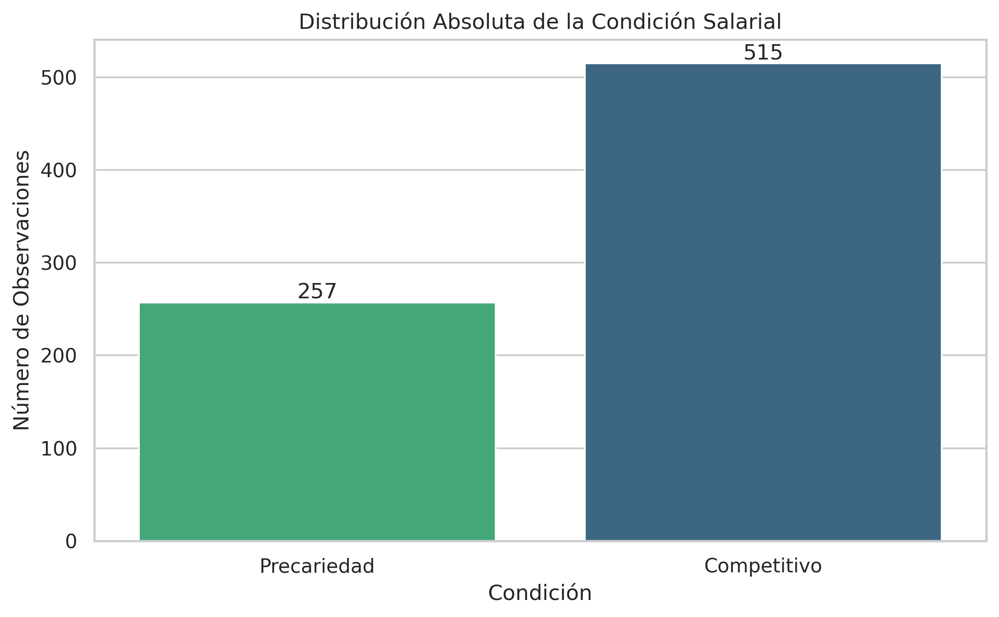

In [20]:
# Cálculo del percentil 33 sobre ingresos positivos
ingresos_positivos = df[df['ingreso'] > 0]['ingreso']
p33 = ingresos_positivos.quantile(0.33)

# Regla de clasificación
df['target_precariedad'] = np.where((df['ingreso'] <= p33) | (df['ingreso'].isna()), 0, 1)

# Estadísticas de la variable objetivo
total_obs = len(df)
ingresos_cero = len(df[df['ingreso'] == 0])
ingresos_pos = len(df[df['ingreso'] > 0])
precariedad_count = len(df[df['target_precariedad'] == 0])
competitivo_count = len(df[df['target_precariedad'] == 1])

display(Markdown(f"""
### Construcción de la variable `target_precariedad`
- **Observaciones totales:** {total_obs}
- **Ingresos iguales a cero:** {ingresos_cero}
- **Ingresos positivos:** {ingresos_pos}
- **Percentil 33 recalculado (ingresos positivos):** ${p33:,.2f} pesos.
- **Clasificados en Precariedad:** {precariedad_count} ({(precariedad_count/total_obs)*100:.1f}%)
- **Clasificados en Competitivo:** {competitivo_count} ({(competitivo_count/total_obs)*100:.1f}%)
"""))

# Gráfico 1: Distribución absoluta
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    x=df['target_precariedad'].map(map_target),
    order=["Precariedad", "Competitivo"],
    hue=df['target_precariedad'].map(map_target),
    palette='viridis',
    legend=False
)
plt.title('Distribución Absoluta de la Condición Salarial')
plt.xlabel('Condición')
plt.ylabel('Número de Observaciones')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_1_distribucion_absoluta.png')
plt.show()

### 5.1.1 Análisis Univariado de Predictores (Características de la Muestra)

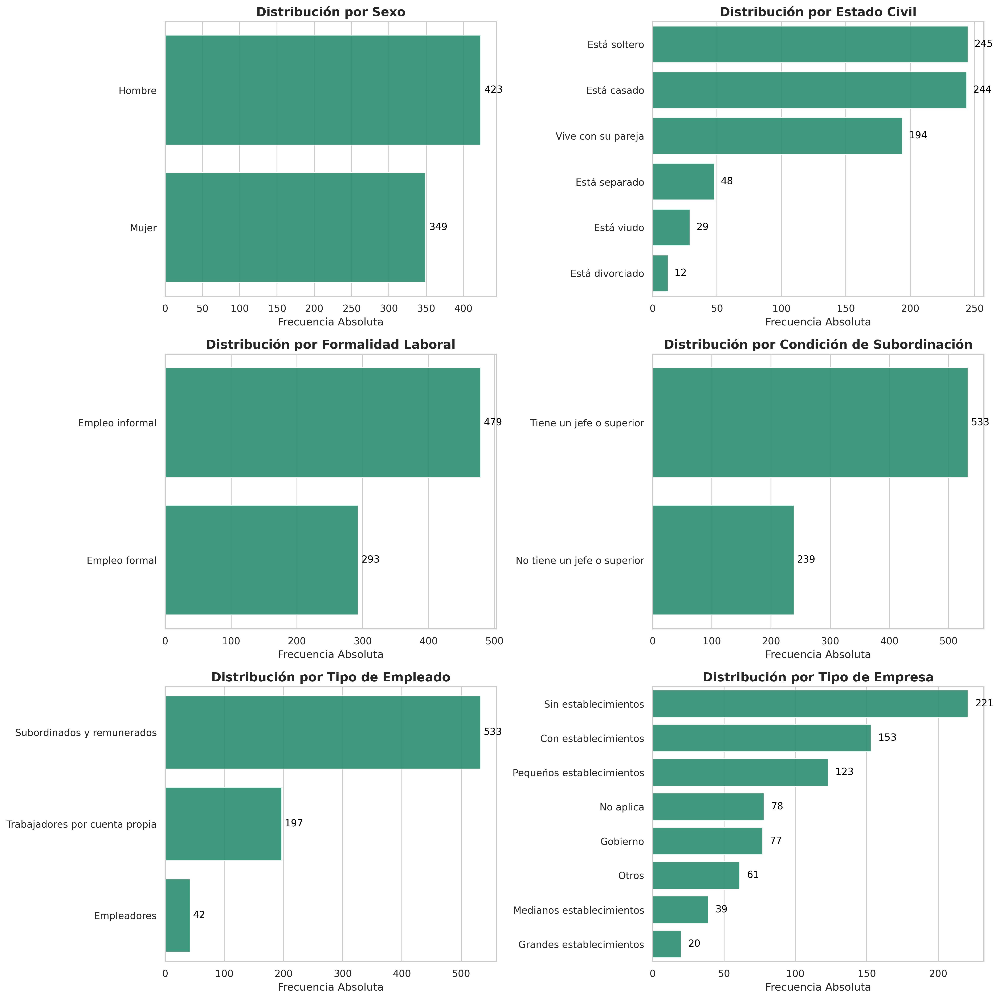

In [21]:
# Preparación de datos univariados con etiquetas descriptivas
df_univ = df.copy()
df_univ['sexo_etiq'] = df_univ['sexo'].map(map_sexo)
df_univ['edo_civil_etiq'] = df_univ['edo_civil'].map(map_edo_civil)
df_univ['empleado_etiq'] = df_univ['tipo_empleado'].map(map_tipo_empleado)
df_univ['empresa_etiq'] = df_univ['tipo_empresa'].map(map_tipo_empresa)
df_univ['formal_etiq'] = df_univ['emp_formal_inf'].map(map_emp_formal_inf)
df_univ['jefe_etiq'] = df_univ['tiene_jefe'].map(map_tiene_jefe)

# 1. Panel de Gráficos Univariados Categóricos
cat_vars = [
    ('sexo_etiq', 'Sexo'),
    ('edo_civil_etiq', 'Estado Civil'),
    ('formal_etiq', 'Formalidad Laboral'),
    ('jefe_etiq', 'Condición de Subordinación'),
    ('empleado_etiq', 'Tipo de Empleado'),
    ('empresa_etiq', 'Tipo de Empresa')
]

fig, axes = plt.subplots(3, 2, figsize=(16, 16))
axes = axes.flatten()
color_base = '#1b9e77'  # Color Competitivo (Teal) como base neutra para la muestra

for i, (var, title) in enumerate(cat_vars):
    # Ordenar por frecuencia para mejor legibilidad
    order = df_univ[var].value_counts().index
    sns.countplot(y=var, data=df_univ, ax=axes[i], order=order, color=color_base, alpha=0.9)
    axes[i].set_title(f'Distribución por {title}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('Frecuencia Absoluta', fontsize=12)
    axes[i].set_ylabel('')

    # Etiquetas de datos en las barras
    for p in axes[i].patches:
        width = p.get_width()
        if width > 0:
            axes[i].annotate(f'{int(width)}',
                             (width + 5, p.get_y() + p.get_height() / 2.),
                             ha='left', va='center', fontsize=11, color='black')

plt.tight_layout()
plt.savefig('figuras_eda/univ_categoricas.png')
plt.show()

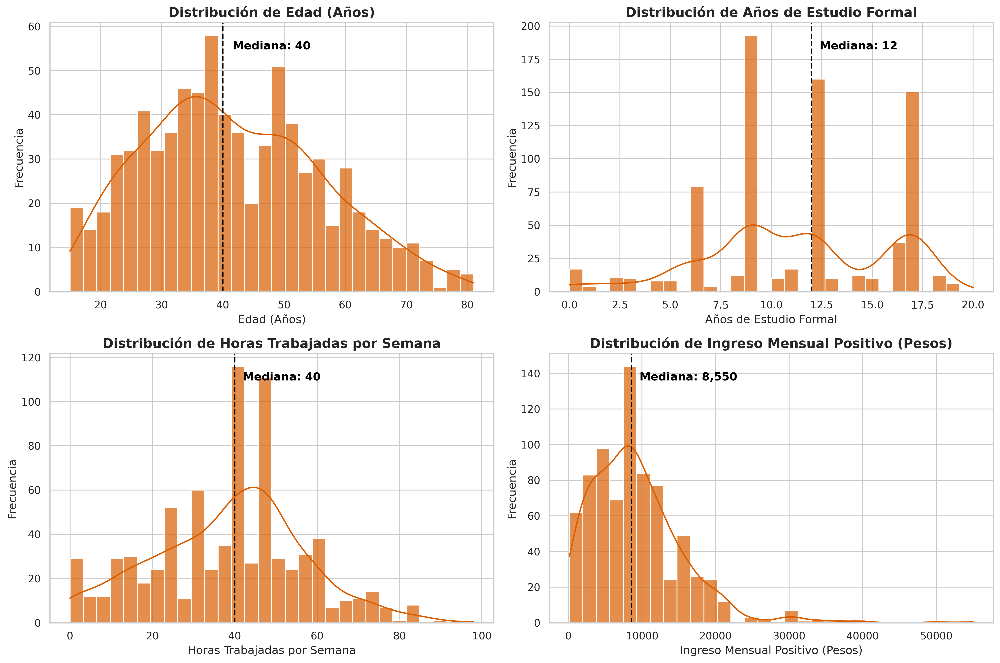

In [22]:
# 2. Panel de Gráficos Univariados Numéricos
num_vars = [
    ('edad', 'Edad (Años)'),
    ('anios_estudio', 'Años de Estudio Formal'),
    ('hrs_trabajo', 'Horas Trabajadas por Semana'),
    ('ingreso', 'Ingreso Mensual Positivo (Pesos)')
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()
color_num = '#d95f02' # Color Precariedad (Óxido) para contraste

for i, (var, title) in enumerate(num_vars):
    # Para el ingreso, filtramos los 0s (si los hay) para ver la distribución real de ganancias
    data_plot = df_univ[df_univ[var] > 0][var] if var == 'ingreso' else df_univ[var]

    sns.histplot(data_plot, kde=True, ax=axes[i], color=color_num, bins=30, alpha=0.7)

    # Añadir línea de la mediana
    mediana = data_plot.median()
    axes[i].axvline(mediana, color='black', linestyle='dashed', linewidth=1.5)
    axes[i].text(mediana + (data_plot.max()*0.02), axes[i].get_ylim()[1]*0.9, f'Mediana: {mediana:,.0f}', color='black', fontweight='bold')

    axes[i].set_title(f'Distribución de {title}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel(title, fontsize=12)
    axes[i].set_ylabel('Frecuencia', fontsize=12)

plt.tight_layout()
plt.savefig('figuras_eda/univ_numericas.png')
plt.show()

## 5.2 Perfil sociodemográfico de la precariedad

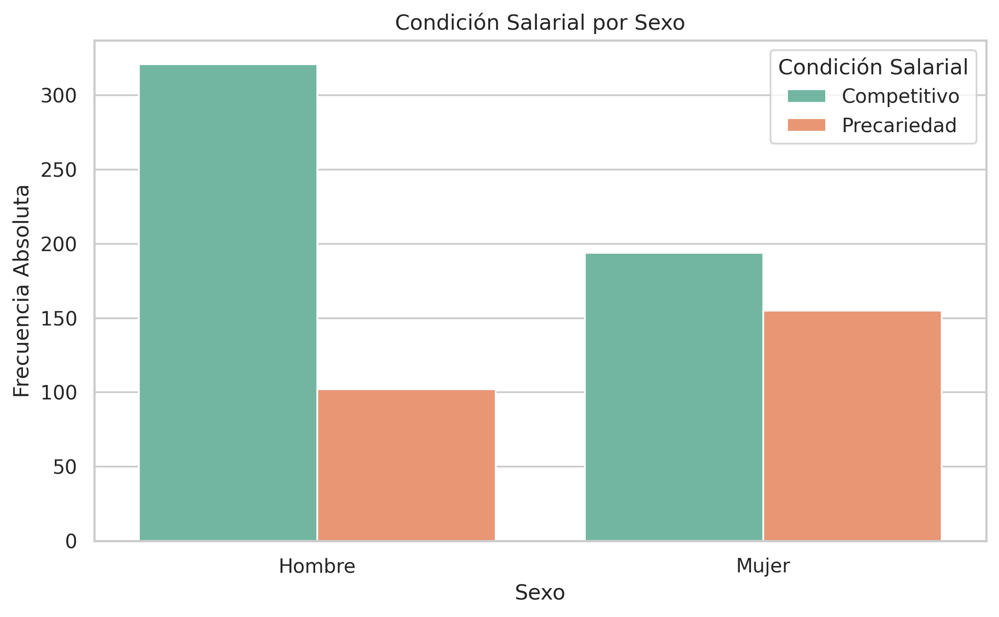

In [23]:
# Preparar dataframe temporal con etiquetas legibles
df_plot = df.copy()
df_plot['sexo_etiq'] = df_plot['sexo'].map(map_sexo)
df_plot['target_etiq'] = df_plot['target_precariedad'].map(map_target)

# Gráfico por Sexo
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_plot, x='sexo_etiq', hue='target_etiq', palette='Set2')
plt.title('Condición Salarial por Sexo')
plt.xlabel('Sexo')
plt.ylabel('Frecuencia Absoluta')
plt.legend(title='Condición Salarial')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_2_sexo.png')
plt.show()

# Cálculo dinámico
mujeres_precarias = len(df_plot[(df_plot['sexo_etiq'] == 'Mujer') & (df_plot['target_etiq'] == 'Precariedad')])
total_mujeres = len(df_plot[df_plot['sexo_etiq'] == 'Mujer'])
prop_mujeres = (mujeres_precarias/total_mujeres)*100 if total_mujeres > 0 else 0

hombres_precarios = len(df_plot[(df_plot['sexo_etiq'] == 'Hombre') & (df_plot['target_etiq'] == 'Precariedad')])
total_hombres = len(df_plot[df_plot['sexo_etiq'] == 'Hombre'])
prop_hombres = (hombres_precarios/total_hombres)*100 if total_hombres > 0 else 0

### Edad
Análisis de la distribución etaria según la condición salarial.

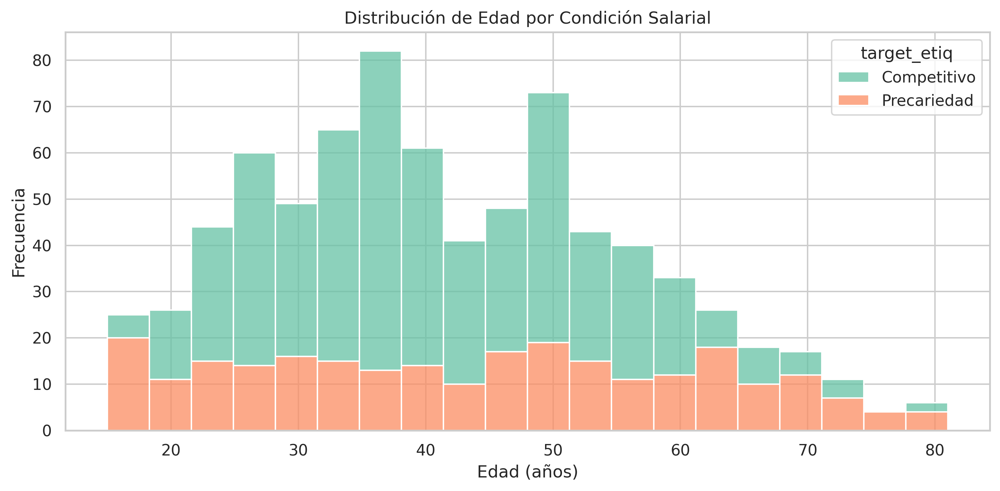

In [24]:
# Edad
plt.figure(figsize=(10, 5))
sns.histplot(data=df_plot, x='edad', hue='target_etiq', multiple='stack', bins=20, palette='Set2')
plt.title('Distribución de Edad por Condición Salarial')
plt.xlabel('Edad (años)')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_2_edad.png')
plt.show()

edad_prec = df_plot[df_plot['target_etiq'] == 'Precariedad']['edad'].median()
edad_comp = df_plot[df_plot['target_etiq'] == 'Competitivo']['edad'].median()

## 5.3 Características laborales y sectoriales

En esta sección se exploran las variables asociadas a la inserción laboral y su relación descriptiva con la precariedad salarial.

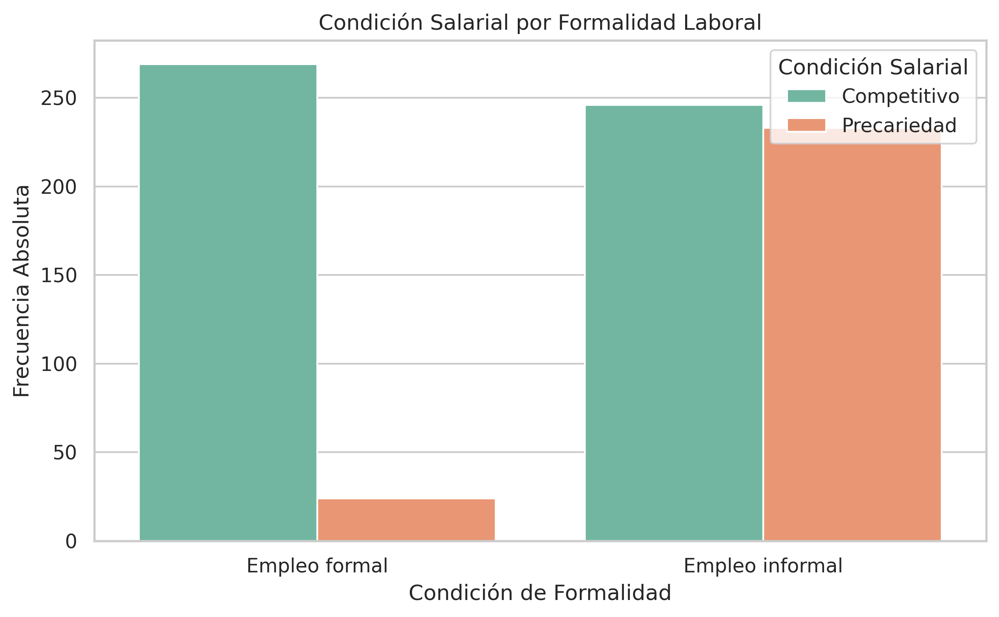

In [25]:
# Preparación de etiquetas 5.3
df_plot['formal_etiq'] = df_plot['emp_formal_inf'].map(map_emp_formal_inf)

# Gráfico Formalidad
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_plot, x='formal_etiq', hue='target_etiq', palette='Set2')
plt.title('Condición Salarial por Formalidad Laboral')
plt.xlabel('Condición de Formalidad')
plt.ylabel('Frecuencia Absoluta')
plt.legend(title='Condición Salarial')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_3_formalidad.png')
plt.show()

inf_prec = len(df_plot[(df_plot['formal_etiq'] == 'Empleo informal') & (df_plot['target_etiq'] == 'Precariedad')])
total_inf = len(df_plot[df_plot['formal_etiq'] == 'Empleo informal'])
prop_inf = (inf_prec/total_inf)*100 if total_inf > 0 else 0

### Estado civil
Análisis descriptivo de la precariedad salarial según el estado civil.

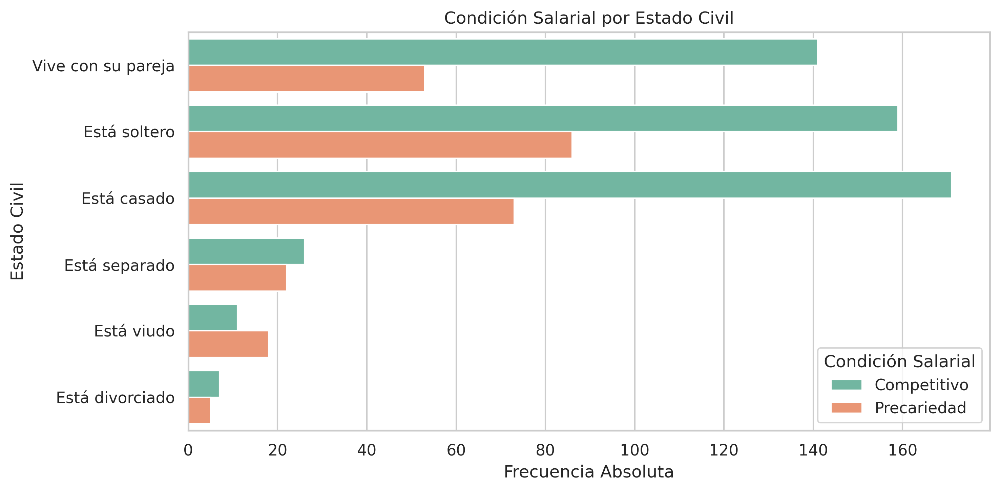

In [26]:
df_plot['edo_civil_etiq'] = df_plot['edo_civil'].map(map_edo_civil)

plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df_plot, y='edo_civil_etiq', hue='target_etiq', palette='Set2')
plt.title('Condición Salarial por Estado Civil')
plt.xlabel('Frecuencia Absoluta')
plt.ylabel('Estado Civil')
plt.legend(title='Condición Salarial')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_2_edo_civil.png')
plt.show()

### Años de estudio
Análisis de la educación formal y su relación con la precariedad salarial.

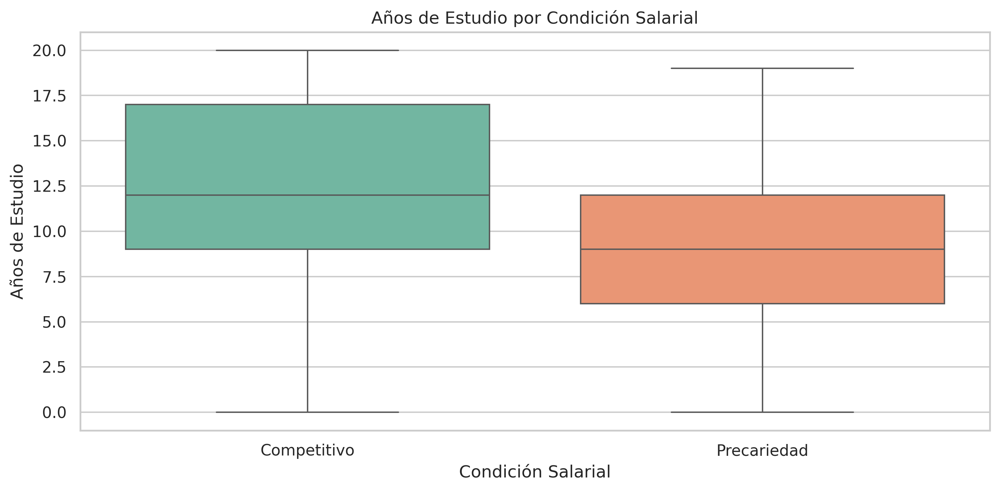

In [27]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_plot, x='target_etiq', y='anios_estudio', hue='target_etiq', palette='Set2', legend=False)
plt.title('Años de Estudio por Condición Salarial')
plt.xlabel('Condición Salarial')
plt.ylabel('Años de Estudio')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_2_anios_estudio.png')
plt.show()

mediana_estudio_prec = df_plot[df_plot['target_etiq'] == 'Precariedad']['anios_estudio'].median()
mediana_estudio_comp = df_plot[df_plot['target_etiq'] == 'Competitivo']['anios_estudio'].median()

### Población económicamente activa
Análisis de la precariedad salarial según la condición de actividad económica.

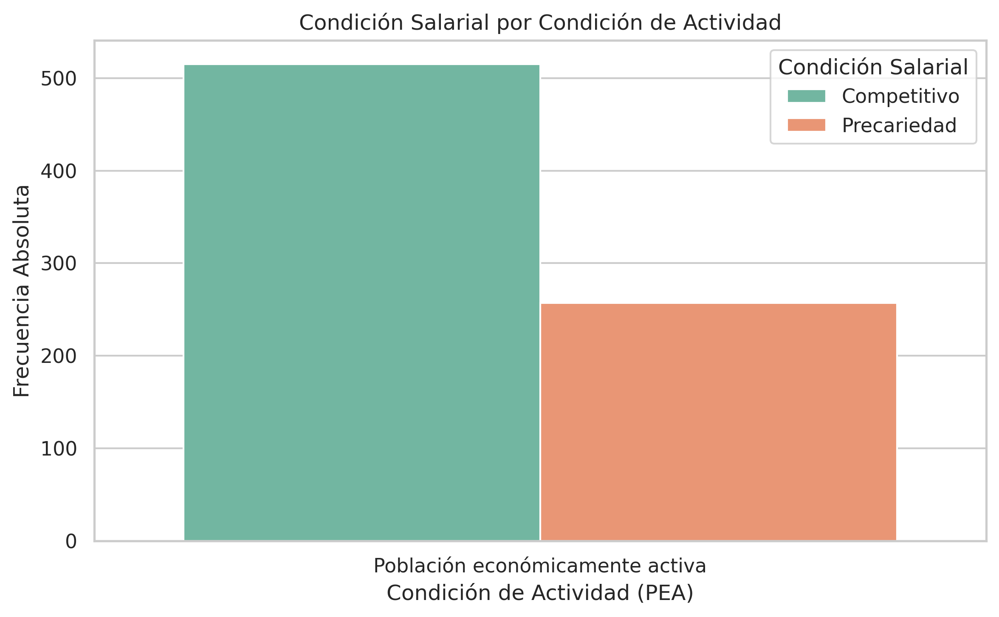

In [28]:
df_plot['pea_etiq'] = df_plot['pea_si_no'].map(map_pea)

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_plot, x='pea_etiq', hue='target_etiq', palette='Set2')
plt.title('Condición Salarial por Condición de Actividad')
plt.xlabel('Condición de Actividad (PEA)')
plt.ylabel('Frecuencia Absoluta')
plt.legend(title='Condición Salarial')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_3_pea.png')
plt.show()

### Tipo de empleado
Distribución de la precariedad según la posición en el trabajo.

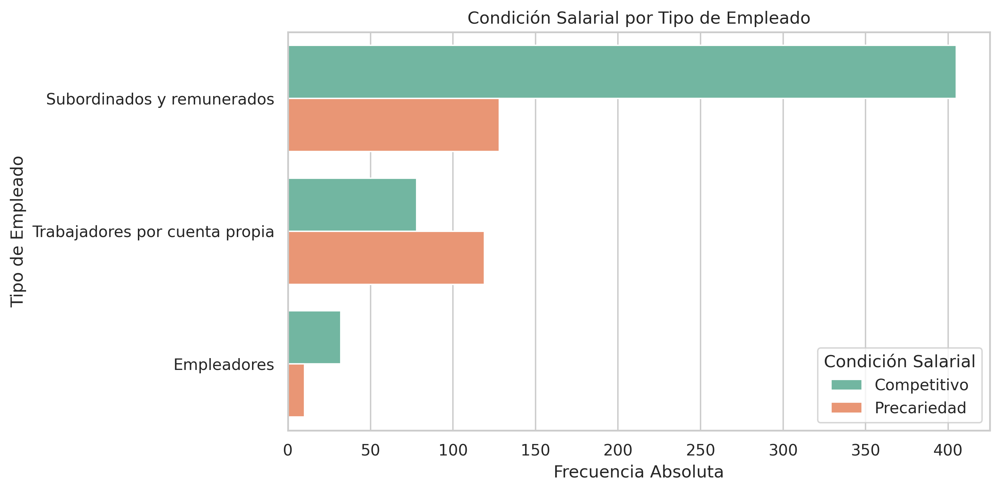

In [29]:
df_plot['empleado_etiq'] = df_plot['tipo_empleado'].map(map_tipo_empleado)

plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df_plot, y='empleado_etiq', hue='target_etiq', palette='Set2')
plt.title('Condición Salarial por Tipo de Empleado')
plt.xlabel('Frecuencia Absoluta')
plt.ylabel('Tipo de Empleado')
plt.legend(title='Condición Salarial')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_3_tipo_empleado.png')
plt.show()

### Tipo de empresa
Incidencia de precariedad salarial de acuerdo con el tamaño o tipo de unidad económica.

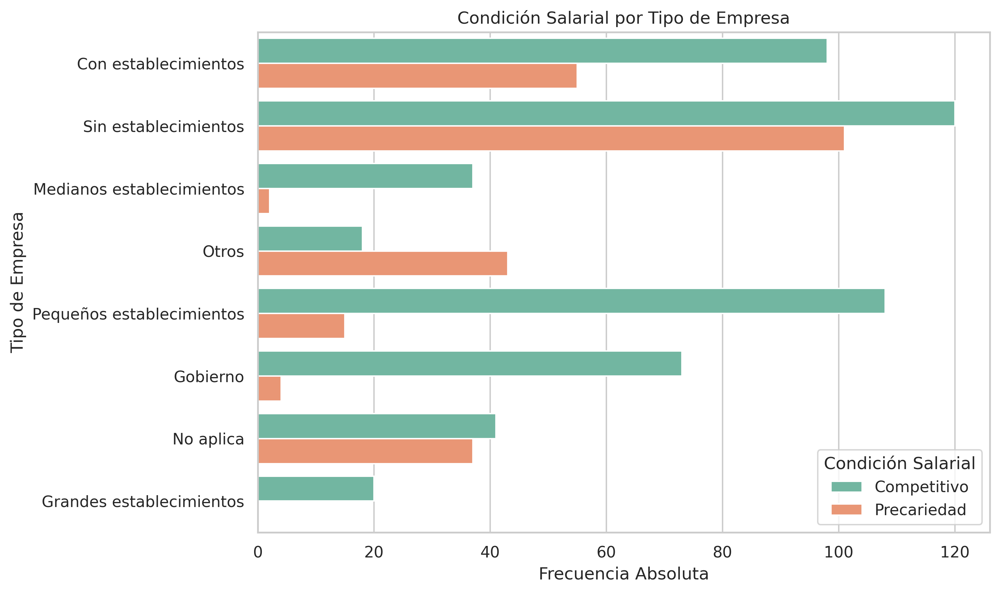

In [30]:
df_plot['empresa_etiq'] = df_plot['tipo_empresa'].map(map_tipo_empresa)

plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df_plot, y='empresa_etiq', hue='target_etiq', palette='Set2')
plt.title('Condición Salarial por Tipo de Empresa')
plt.xlabel('Frecuencia Absoluta')
plt.ylabel('Tipo de Empresa')
plt.legend(title='Condición Salarial')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_3_tipo_empresa.png')
plt.show()

### Horas trabajadas
Análisis comparativo de las jornadas laborales semanales.

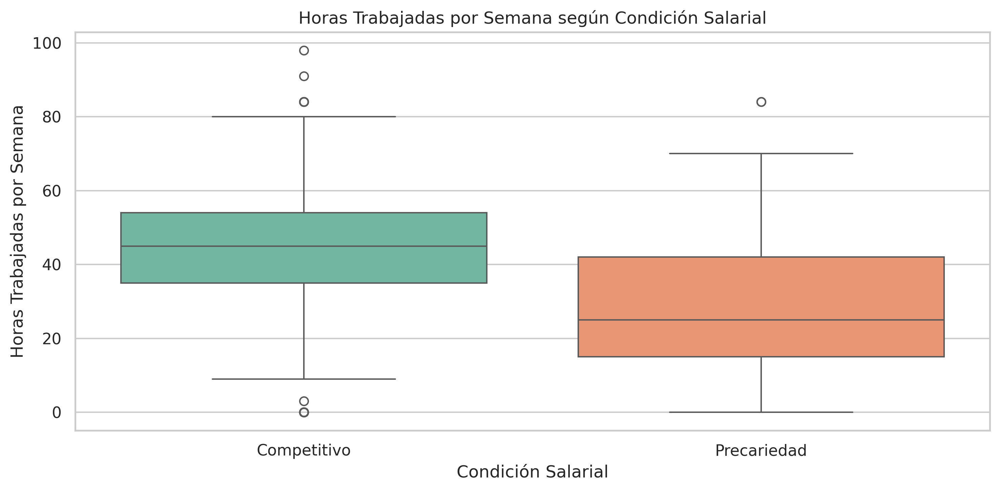

In [31]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_plot, x='target_etiq', y='hrs_trabajo', hue='target_etiq', palette='Set2', legend=False)
plt.title('Horas Trabajadas por Semana según Condición Salarial')
plt.xlabel('Condición Salarial')
plt.ylabel('Horas Trabajadas por Semana')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_3_hrs_trabajo.png')
plt.show()

mediana_hrs_prec = df_plot[df_plot['target_etiq'] == 'Precariedad']['hrs_trabajo'].median()
mediana_hrs_comp = df_plot[df_plot['target_etiq'] == 'Competitivo']['hrs_trabajo'].median()

### Tiene jefe o superior
Relevancia de la subordinación directa en el lugar de trabajo.

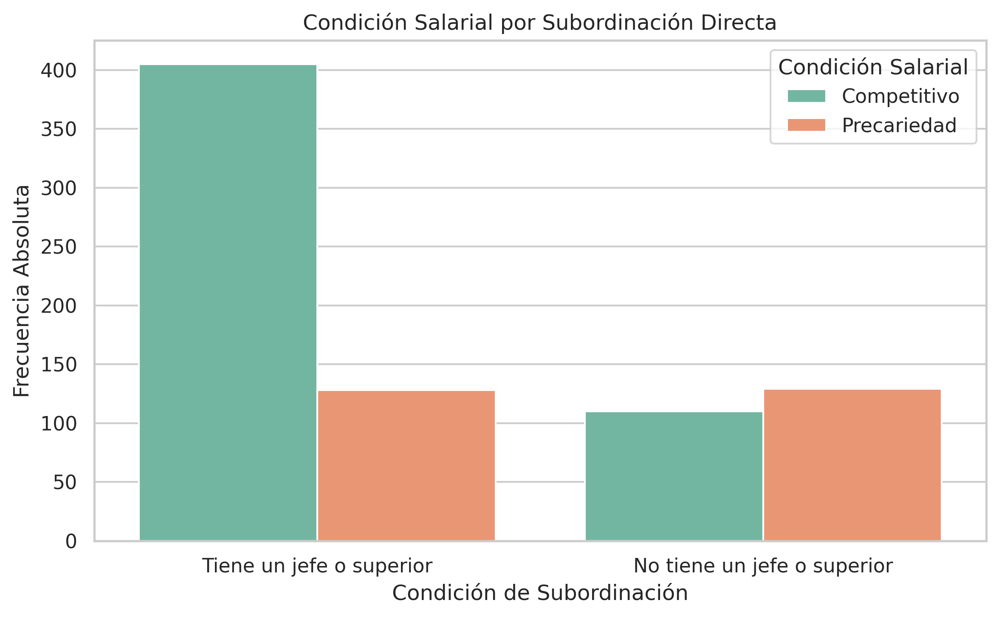

In [32]:
df_plot['jefe_etiq'] = df_plot['tiene_jefe'].map(map_tiene_jefe)

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_plot, x='jefe_etiq', hue='target_etiq', palette='Set2')
plt.title('Condición Salarial por Subordinación Directa')
plt.xlabel('Condición de Subordinación')
plt.ylabel('Frecuencia Absoluta')
plt.legend(title='Condición Salarial')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_3_tiene_jefe.png')
plt.show()

### Ingreso
Comportamiento descriptivo de la variable original.

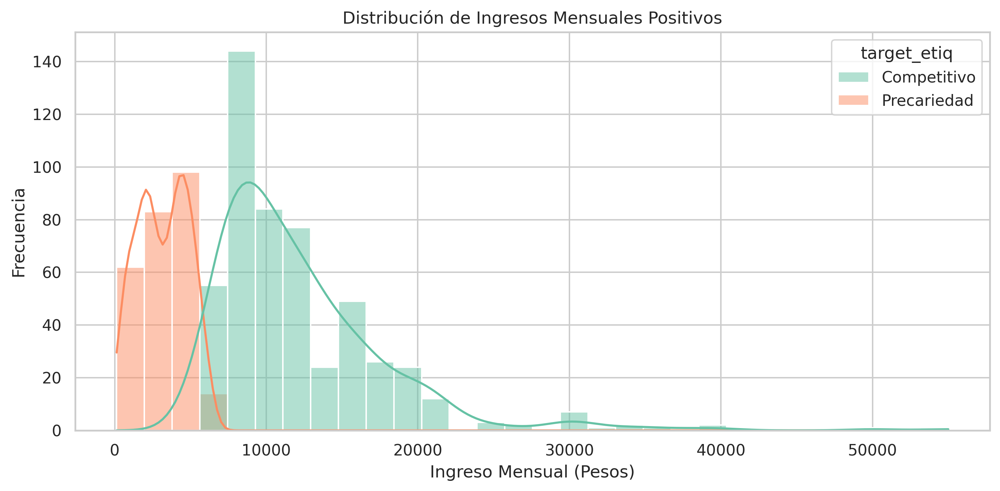

In [33]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df_plot[df_plot['ingreso'] > 0], x='ingreso', hue='target_etiq', bins=30, kde=True, palette='Set2')
plt.title('Distribución de Ingresos Mensuales Positivos')
plt.xlabel('Ingreso Mensual (Pesos)')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_3_ingreso.png')
plt.show()

### 5.3.0 Análisis Bivariado Complementario (Distribuciones y Proporciones)

/tmp/ipykernel_1772/415469320.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_viz, x='rango_estudio', y='ingreso', palette='Set2')


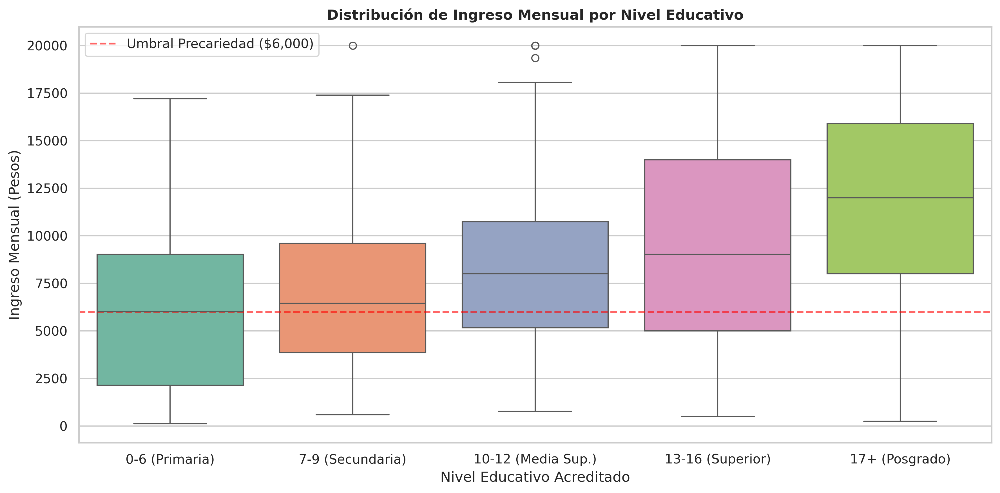

In [34]:
# 1. Distribución del Ingreso por Nivel Educativo (Boxplot)
# Creación de rangos educativos temporales para mejor lectura
bins_edu = [-1, 6, 9, 12, 16, 100]
labels_edu = ['0-6 (Primaria)', '7-9 (Secundaria)', '10-12 (Media Sup.)', '13-16 (Superior)', '17+ (Posgrado)']
df_plot['rango_estudio'] = pd.cut(df_plot['anios_estudio'], bins=bins_edu, labels=labels_edu)

# Filtrar el percentil 95 para evitar que los valores atípicos aplasten el gráfico
limite_ingreso = df_plot['ingreso'].quantile(0.95)
df_viz = df_plot[df_plot['ingreso'] <= limite_ingreso]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_viz, x='rango_estudio', y='ingreso', palette='Set2')
plt.title('Distribución de Ingreso Mensual por Nivel Educativo', fontweight='bold')
plt.xlabel('Nivel Educativo Acreditado')
plt.ylabel('Ingreso Mensual (Pesos)')
# Línea roja de precariedad
plt.axhline(y=6000, color='red', linestyle='--', alpha=0.6, label='Umbral Precariedad ($6,000)')
plt.legend()
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_3_0_ingreso_educacion.png')
plt.show()

/tmp/ipykernel_1772/2584654780.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_viz, x='formal_etiq', y='ingreso', palette='Set2', inner='quartile')


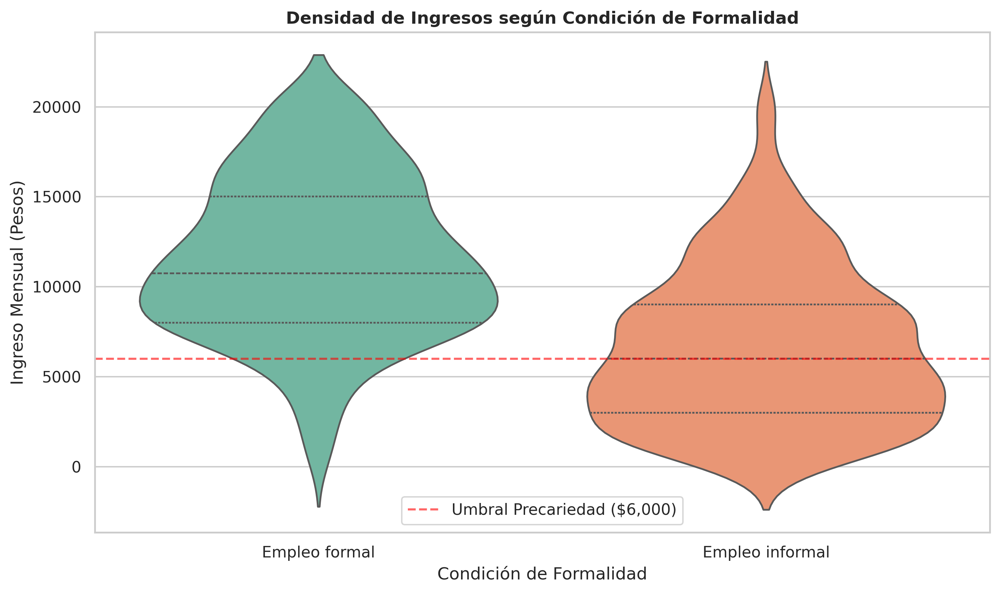

In [35]:
# 2. Distribución y Densidad del Ingreso por Formalidad Laboral (Violin Plot)
plt.figure(figsize=(10, 6))
sns.violinplot(data=df_viz, x='formal_etiq', y='ingreso', palette='Set2', inner='quartile')
plt.title('Densidad de Ingresos según Condición de Formalidad', fontweight='bold')
plt.xlabel('Condición de Formalidad')
plt.ylabel('Ingreso Mensual (Pesos)')
plt.axhline(y=6000, color='red', linestyle='--', alpha=0.6, label='Umbral Precariedad ($6,000)')
plt.legend()
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_3_0_ingreso_formalidad.png')
plt.show()

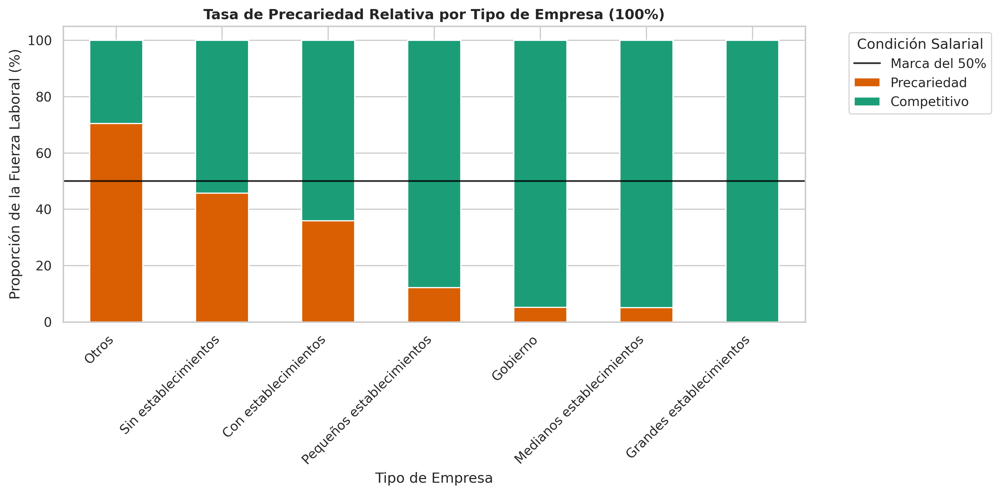

In [36]:
# 3. Proporción Relativa (Riesgo) de Precariedad por Tipo de Empresa (100% Stacked Bar)
# Se calculan las proporciones en lugar de los absolutos
props = df_plot[df_plot['empresa_etiq'] != 'No aplica'].groupby('empresa_etiq')['target_etiq'].value_counts(normalize=True).unstack() * 100

# Ordenar por mayor tasa de precariedad
props = props.sort_values(by='Precariedad', ascending=False)

# Definir colores semánticos (verde competitivo, naranja precariedad)
color_precariedad = '#d95f02'
color_competitivo = '#1b9e77'

props[['Precariedad', 'Competitivo']].plot(kind='bar', stacked=True, color=[color_precariedad, color_competitivo], figsize=(12, 6), edgecolor='white')
plt.title('Tasa de Precariedad Relativa por Tipo de Empresa (100%)', fontweight='bold')
plt.ylabel('Proporción de la Fuerza Laboral (%)')
plt.xlabel('Tipo de Empresa')
plt.axhline(50, color='black', linestyle='-', alpha=0.8, label='Marca del 50%')
plt.legend(title='Condición Salarial', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_3_0_proporcion_empresa.png')
plt.show()

### 5.3.1 Análisis Multivariado: Intersecciones de la Precariedad

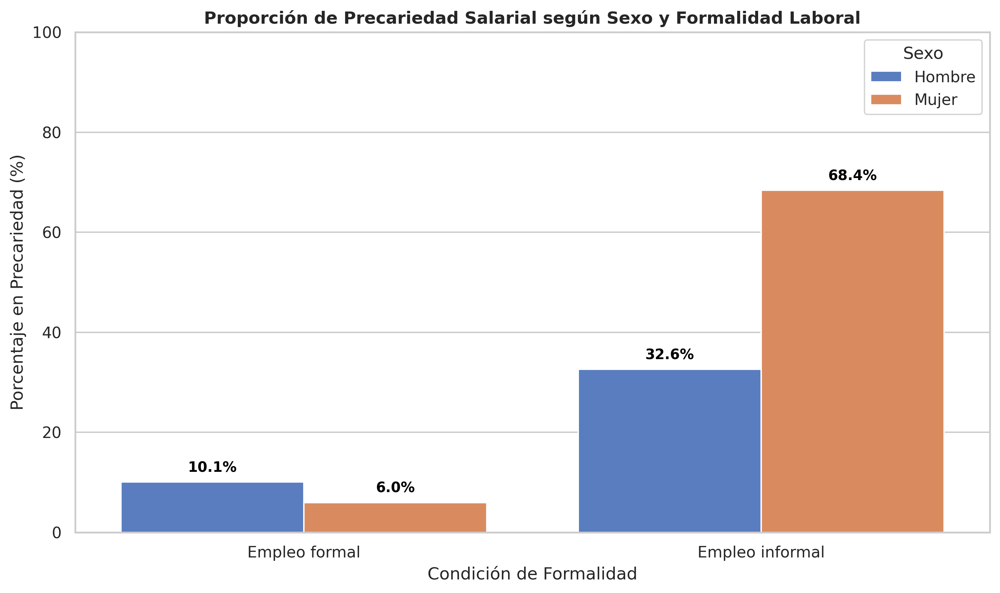

In [37]:
# Configuración de paleta semántica institucional
paleta_tesis = {'Precariedad': '#d95f02', 'Competitivo': '#1b9e77'}

# 1. Perfil de precariedad por sexo y formalidad
# Calculamos los porcentajes de precariedad por cada subgrupo
subset = df_plot[df_plot['formal_etiq'] != 'No aplica']
grouped = subset.groupby(['formal_etiq', 'sexo_etiq'])['target_precariedad'].agg(
    pct_precariedad=lambda x: (1 - x.mean()) * 100,
    total='count'
).reset_index()

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=grouped, x='formal_etiq', y='pct_precariedad', hue='sexo_etiq', palette='muted')
plt.title('Proporción de Precariedad Salarial según Sexo y Formalidad Laboral', fontweight='bold')
plt.xlabel('Condición de Formalidad')
plt.ylabel('Porcentaje en Precariedad (%)')
plt.ylim(0, 100)

# Añadir anotaciones directas
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.1f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', color='black', xytext=(0, 5), textcoords='offset points')

plt.legend(title='Sexo')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_3_multivariado_sexo_formalidad.png')
plt.show()


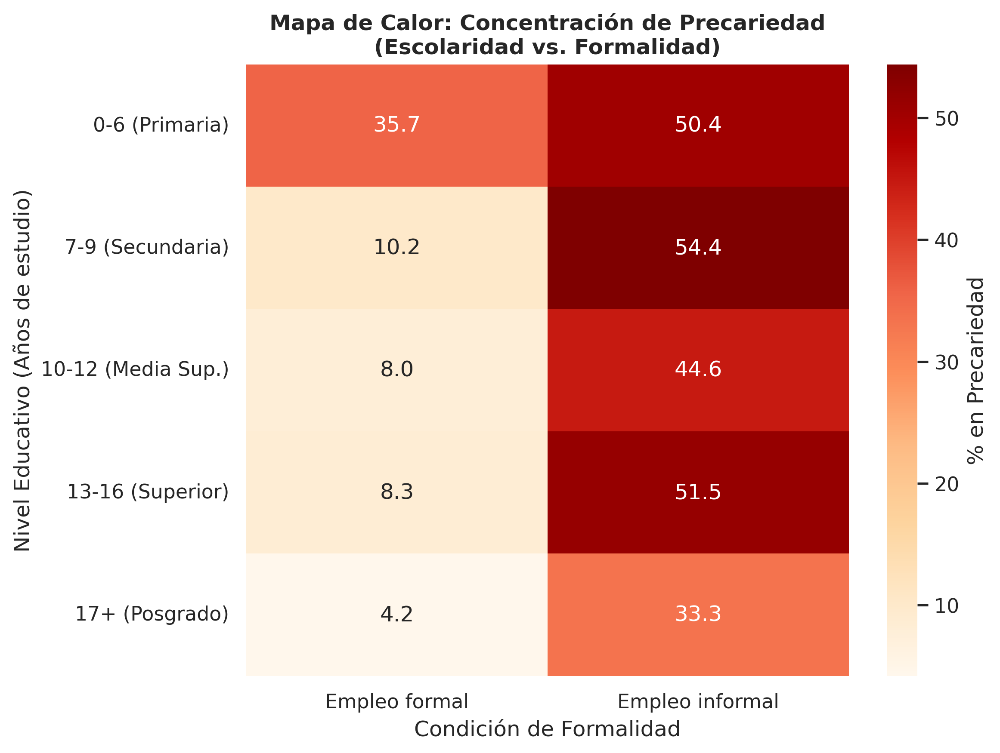

In [38]:
# 2. Mapa de Calor: Escolaridad vs Formalidad
# Discretizar años de estudio en categorías comprensibles
bins_edu = [-1, 6, 9, 12, 16, 100]
labels_edu = ['0-6 (Primaria)', '7-9 (Secundaria)', '10-12 (Media Sup.)', '13-16 (Superior)', '17+ (Posgrado)']
df_plot['rango_estudio'] = pd.cut(df_plot['anios_estudio'], bins=bins_edu, labels=labels_edu)

# Calcular porcentaje de precariedad (inverso a la media de target_precariedad)
heatmap_data = df_plot[df_plot['formal_etiq'] != 'No aplica'].groupby(['rango_estudio', 'formal_etiq'], observed=False)['target_precariedad'].apply(lambda x: (1 - x.mean()) * 100).unstack()

plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".1f", cmap="OrRd", cbar_kws={'label': '% en Precariedad'})
plt.title('Mapa de Calor: Concentración de Precariedad\n(Escolaridad vs. Formalidad)', fontweight='bold')
plt.xlabel('Condición de Formalidad')
plt.ylabel('Nivel Educativo (Años de estudio)')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_3_multivariado_heatmap.png')
plt.show()


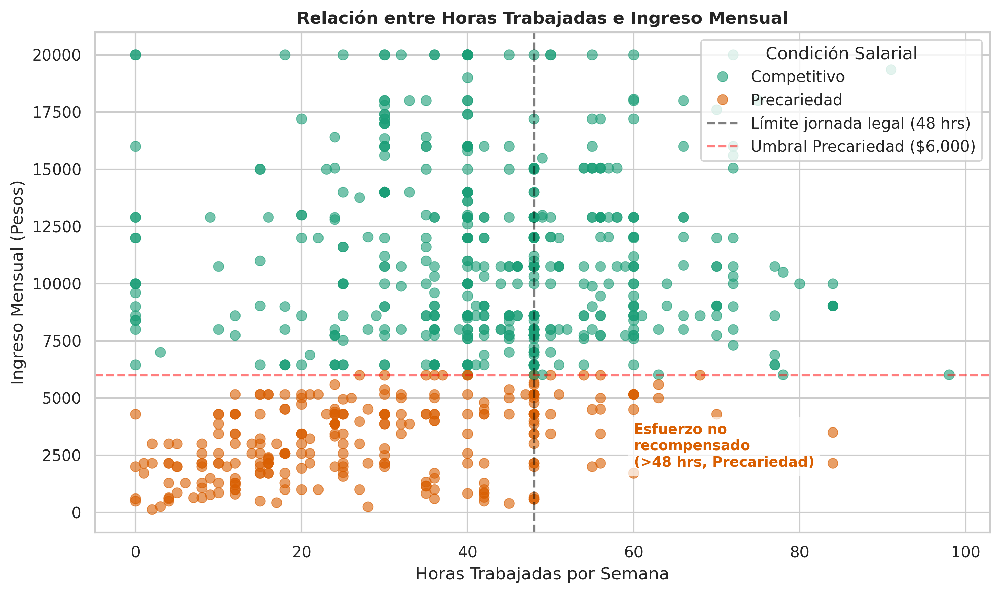

In [39]:
# 3. Scatterplot de Cuadrantes: Horas Trabajadas vs Ingreso
plt.figure(figsize=(10, 6))
# Filtrar ingresos extremadamente altos para mejor visualización descriptiva (ej. truncar percentil 99 para el zoom)
max_ingreso_viz = df_plot['ingreso'].quantile(0.95)
data_scatter = df_plot[(df_plot['ingreso'] > 0) & (df_plot['ingreso'] <= max_ingreso_viz)]

sns.scatterplot(data=data_scatter, x='hrs_trabajo', y='ingreso', hue='target_etiq',
                palette=paleta_tesis, alpha=0.6, edgecolor=None, s=50)

# Líneas de cuadrante
plt.axvline(x=48, color='black', linestyle='--', alpha=0.5, label='Límite jornada legal (48 hrs)')
plt.axhline(y=6000, color='red', linestyle='--', alpha=0.5, label='Umbral Precariedad ($6,000)')

plt.title('Relación entre Horas Trabajadas e Ingreso Mensual', fontweight='bold')
plt.xlabel('Horas Trabajadas por Semana')
plt.ylabel('Ingreso Mensual (Pesos)')
plt.legend(title='Condición Salarial', loc='upper right')

# Anotación del cuadrante crítico
plt.text(60, 2000, 'Esfuerzo no\nrecompensado\n(>48 hrs, Precariedad)', color='#d95f02', fontsize=10, fontweight='bold', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

plt.tight_layout()
plt.savefig('figuras_eda/fig_5_3_multivariado_scatter_horas.png')
plt.show()


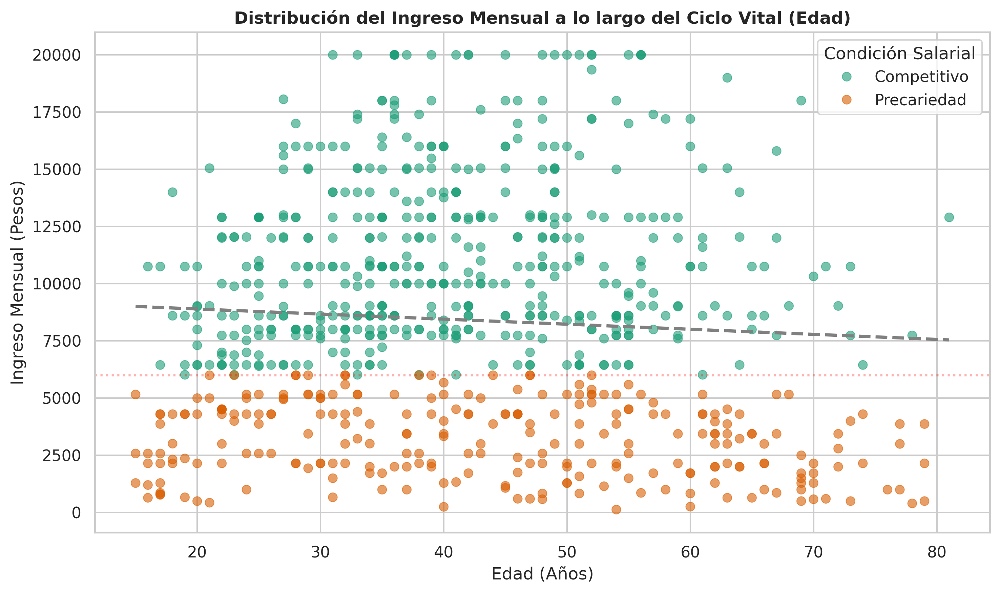

In [40]:
# 4. Scatterplot: Edad vs Ingreso
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data_scatter, x='edad', y='ingreso', hue='target_etiq',
                palette=paleta_tesis, alpha=0.6, edgecolor=None, s=40)

# Línea de tendencia (Suavizado LOESS/LOWESS descriptivo para la tendencia central general)
sns.regplot(data=data_scatter, x='edad', y='ingreso', scatter=False, color='gray', line_kws={'linestyle':'--'}, ci=None)

plt.title('Distribución del Ingreso Mensual a lo largo del Ciclo Vital (Edad)', fontweight='bold')
plt.xlabel('Edad (Años)')
plt.ylabel('Ingreso Mensual (Pesos)')
plt.axhline(y=6000, color='red', linestyle=':', alpha=0.3)
plt.legend(title='Condición Salarial')

plt.tight_layout()
plt.savefig('figuras_eda/fig_5_3_multivariado_scatter_edad.png')
plt.show()


## 5.4 Análisis bivariado, matrices de correlación y hallazgos

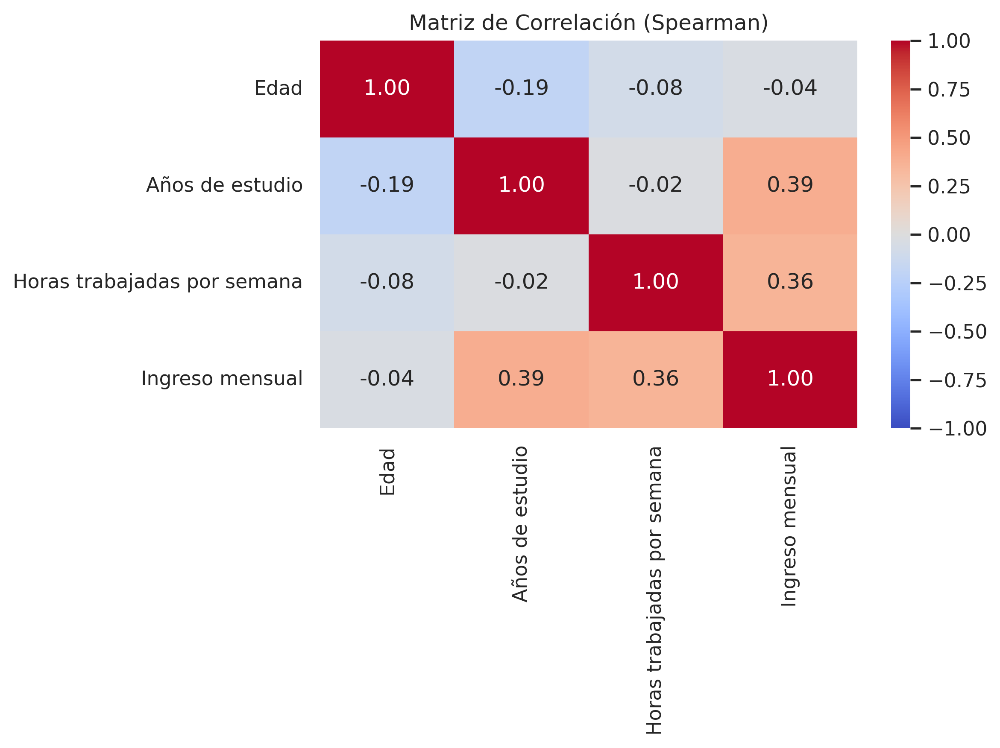

In [41]:
# Variables cuantitativas para correlación
cuantitativas = ['edad', 'anios_estudio', 'hrs_trabajo', 'ingreso']
corr_df = df[cuantitativas].rename(columns={
    'edad': 'Edad',
    'anios_estudio': 'Años de estudio',
    'hrs_trabajo': 'Horas trabajadas por semana',
    'ingreso': 'Ingreso mensual'
})

# Matriz de correlación de Spearman (más robusta para ingresos con asimetría y valores extremos)
matriz_corr = corr_df.corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title('Matriz de Correlación (Spearman)')
plt.tight_layout()
plt.savefig('figuras_eda/fig_5_4_matriz_correlacion.png')
plt.show()

## Tablas Descriptivas de Resumen

A continuación se presentan las tablas consolidadas que resumen la estructura de la muestra, los valores faltantes, las estadísticas descriptivas y las proporciones de precariedad por variable categórica.

In [42]:
# 1 y 2. Tabla de valores faltantes
tabla_faltantes = df.isnull().sum().reset_index()
tabla_faltantes.columns = ['Variable', 'Valores Faltantes']
tabla_faltantes['Porcentaje (%)'] = (tabla_faltantes['Valores Faltantes'] / len(df)) * 100
display(Markdown("### Tabla 1. Valores faltantes por variable"))
display(tabla_faltantes)

# 3. Tabla de distribución de target_precariedad
tabla_target = df_plot['target_etiq'].value_counts().reset_index()
tabla_target.columns = ['Condición Salarial', 'Frecuencia']
tabla_target['Porcentaje (%)'] = (tabla_target['Frecuencia'] / len(df_plot)) * 100
display(Markdown("### Tabla 2. Distribución de la variable objetivo (target_precariedad)"))
display(tabla_target)

# 4. Tabla descriptiva de variables cuantitativas
tabla_cuant = df_plot[['edad', 'anios_estudio', 'hrs_trabajo', 'ingreso']].describe().T
display(Markdown("### Tabla 3. Estadísticas descriptivas de variables cuantitativas"))
display(tabla_cuant)

# 5 y 6. Tablas de proporción de precariedad por variables categóricas clave

# Sexo
tabla_sexo = pd.crosstab(df_plot['sexo_etiq'], df_plot['target_etiq'], margins=True)
tabla_sexo_pct = pd.crosstab(df_plot['sexo_etiq'], df_plot['target_etiq'], normalize='index') * 100
display(Markdown("### Tabla 4. Frecuencia y Proporción de precariedad por Sexo"))
display(tabla_sexo)
display(tabla_sexo_pct)

# Formalidad Laboral
tabla_formal_pct = pd.crosstab(df_plot['formal_etiq'], df_plot['target_etiq'], normalize='index') * 100
display(Markdown("### Tabla 6. Proporción de precariedad por Formalidad Laboral (%)"))
display(tabla_formal_pct)

# Tipo de Empleado
tabla_emp_pct = pd.crosstab(df_plot['empleado_etiq'], df_plot['target_etiq'], normalize='index') * 100
display(Markdown("### Tabla 7. Proporción de precariedad por Tipo de Empleado (%)"))
display(tabla_emp_pct)

### Tabla 1. Valores faltantes por variable

,Variable,Valores Faltantes,Porcentaje (%)
0,sexo,0,0.0
1,edad,0,0.0
2,edo_civil,0,0.0
3,pea_si_no,0,0.0
4,tipo_empleado,0,0.0
5,tipo_empresa,0,0.0
6,anios_estudio,0,0.0
7,hrs_trabajo,0,0.0
8,ingreso,0,0.0
9,emp_formal_inf,0,0.0


### Tabla 2. Distribución de la variable objetivo (target_precariedad)

,Condición Salarial,Frecuencia,Porcentaje (%)
0,Competitivo,515,66.709845
1,Precariedad,257,33.290155


### Tabla 3. Estadísticas descriptivas de variables cuantitativas

...

target_etiq,Competitivo,Precariedad
sexo_etiq,,
Hombre,75.886525,24.113475
Mujer,55.587393,44.412607


### Tabla 6. Proporción de precariedad por Formalidad Laboral (%)

target_etiq,Competitivo,Precariedad
formal_etiq,,
Empleo formal,91.808874,8.191126
Empleo informal,51.356994,48.643006


### Tabla 7. Proporción de precariedad por Tipo de Empleado (%)

target_etiq,Competitivo,Precariedad
empleado_etiq,,
Empleadores,76.190476,23.809524
Subordinados y remunerados,75.984991,24.015009
Trabajadores por cuenta propia,39.593909,60.406091


### Análisis Bivariado Complementario Adicional

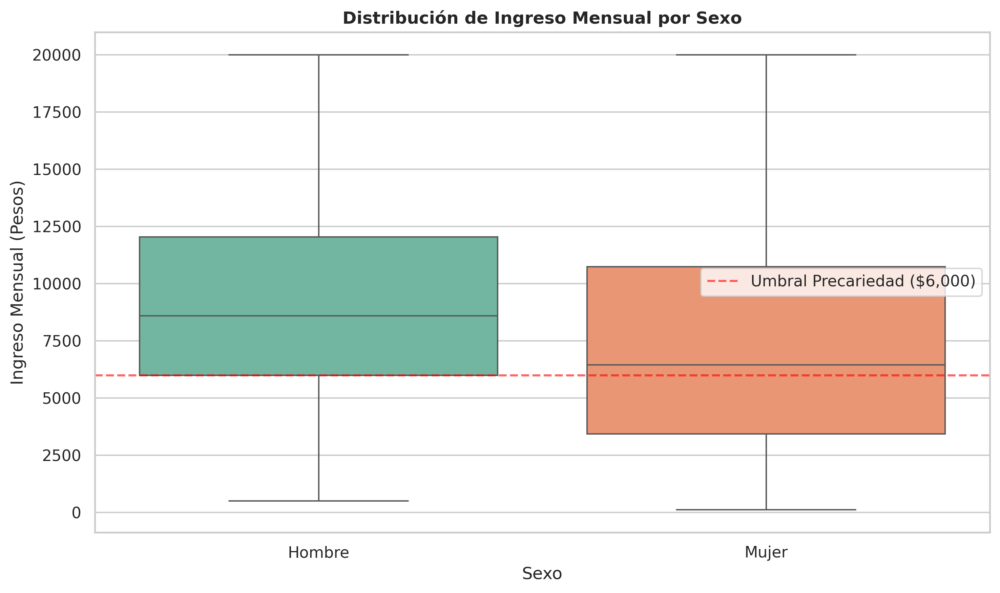

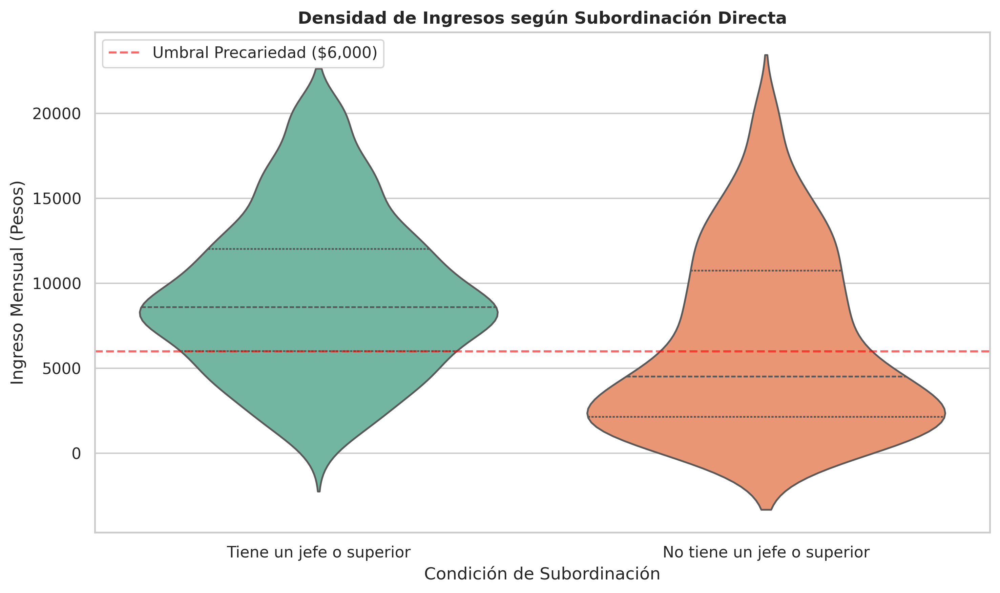

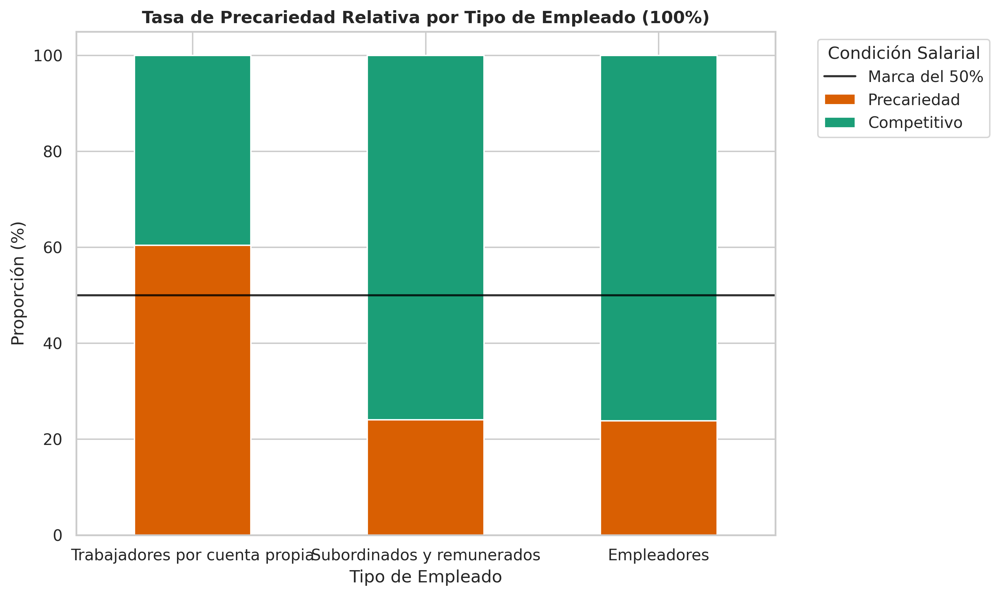

In [43]:
# Configuración de colores
color_precariedad = '#d95f02'
color_competitivo = '#1b9e77'

# Filtrar outliers de ingreso (percentil 95) para no distorsionar las visualizaciones de caja/violín
limite_ingreso = df_plot['ingreso'].quantile(0.95)
df_viz = df_plot[df_plot['ingreso'] <= limite_ingreso]

# =============================================================================
# 1. Ingreso vs Sexo (Boxplot)
# =============================================================================
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_viz, x='sexo_etiq', y='ingreso', hue='sexo_etiq', palette='Set2', legend=False)
plt.title('Distribución de Ingreso Mensual por Sexo', fontweight='bold')
plt.xlabel('Sexo')
plt.ylabel('Ingreso Mensual (Pesos)')
plt.axhline(y=6000, color='red', linestyle='--', alpha=0.6, label='Umbral Precariedad ($6,000)')
plt.legend()
plt.tight_layout()
plt.show()

# =============================================================================
# 2. Ingreso vs Subordinación (Violinplot)
# =============================================================================
plt.figure(figsize=(10, 6))
sns.violinplot(data=df_viz, x='jefe_etiq', y='ingreso', hue='jefe_etiq', palette='Set2', inner='quartile', legend=False)
plt.title('Densidad de Ingresos según Subordinación Directa', fontweight='bold')
plt.xlabel('Condición de Subordinación')
plt.ylabel('Ingreso Mensual (Pesos)')
plt.axhline(y=6000, color='red', linestyle='--', alpha=0.6, label='Umbral Precariedad ($6,000)')
plt.legend()
plt.tight_layout()
plt.show()

# =============================================================================
# 3. Proporción de Precariedad por Tipo de Empleado (100% Stacked Bar)
# =============================================================================
# Calculamos la proporción relativa por categoría
props_emp = df_plot[df_plot['empleado_etiq'] != 'No aplica'].groupby('empleado_etiq')['target_etiq'].value_counts(normalize=True).unstack() * 100
props_emp = props_emp.sort_values(by='Precariedad', ascending=False)

props_emp[['Precariedad', 'Competitivo']].plot(
    kind='bar', stacked=True,
    color=[color_precariedad, color_competitivo],
    figsize=(10, 6), edgecolor='white'
)
plt.title('Tasa de Precariedad Relativa por Tipo de Empleado (100%)', fontweight='bold')
plt.ylabel('Proporción (%)')
plt.xlabel('Tipo de Empleado')
plt.axhline(50, color='black', linestyle='-', alpha=0.8, label='Marca del 50%')
plt.legend(title='Condición Salarial', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

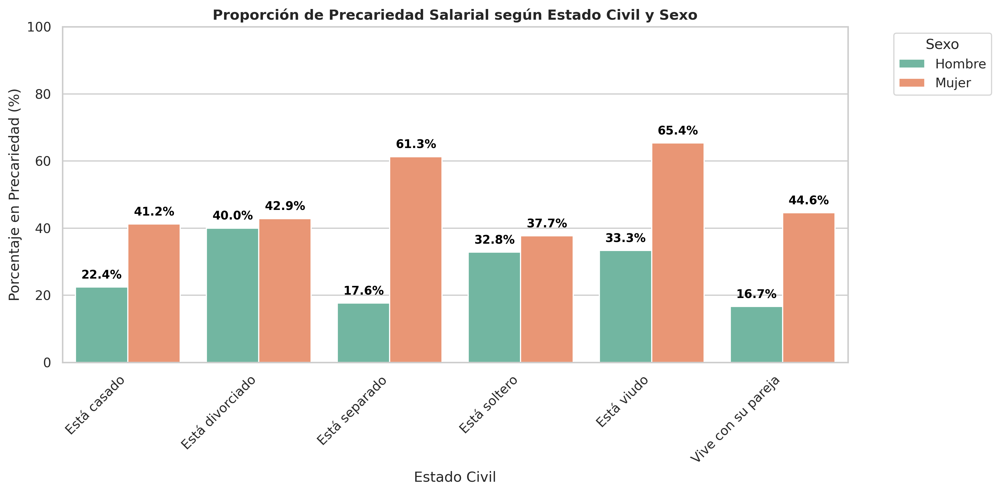

**Insight (Precariedad vs Sexo y Estado Civil):** Este análisis interseccional permite observar cómo las dinámicas sociodemográficas conjuntas afectan el riesgo salarial. Destaca visualmente cómo ciertas categorías civiles (como estar separado, divorciado o viviendo en pareja) pueden penalizar económicamente de manera asimétrica a mujeres en comparación con los hombres, reforzando la hipótesis de la acumulación de vulnerabilidades por género.

In [44]:
# =============================================================================
# 4. Proporción de Precariedad por Sexo y Estado Civil
# =============================================================================
# Calculamos los porcentajes de precariedad por cada subgrupo
grouped_sex_edo = df_plot.groupby(['edo_civil_etiq', 'sexo_etiq'])['target_precariedad'].agg(
    pct_precariedad=lambda x: (1 - x.mean()) * 100
).reset_index()

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=grouped_sex_edo, x='edo_civil_etiq', y='pct_precariedad', hue='sexo_etiq', palette='Set2')
plt.title('Proporción de Precariedad Salarial según Estado Civil y Sexo', fontweight='bold')
plt.xlabel('Estado Civil')
plt.ylabel('Porcentaje en Precariedad (%)')
plt.ylim(0, 100)

# Añadir anotaciones directas en las barras
for p in ax.patches:
    height = p.get_height()
    # Control para evitar nan si hay barras vacías
    if pd.notnull(height) and height > 0:
        ax.annotate(f'{height:.1f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', color='black',
                    xytext=(0, 5), textcoords='offset points')

plt.legend(title='Sexo', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

display(Markdown('**Insight (Precariedad vs Sexo y Estado Civil):** Este análisis interseccional permite observar cómo las dinámicas sociodemográficas conjuntas afectan el riesgo salarial. Destaca visualmente cómo ciertas categorías civiles (como estar separado, divorciado o viviendo en pareja) pueden penalizar económicamente de manera asimétrica a mujeres en comparación con los hombres, reforzando la hipótesis de la acumulación de vulnerabilidades por género.'))

# CAPÍTULO 6. Modelado predictivo e Inteligencia Artificial Explicable

In [45]:
# ==============================================================================
# CELDA 1: CONFIGURACIÓN INICIAL E IMPORTACIÓN DE LIBRERÍAS
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

import shap

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

In [46]:
df = pd.read_csv('/content/enoe_def_clean.csv')

In [47]:
df.drop(columns=['pea_si_no'], axis = 1)

,sexo,edad,edo_civil,tipo_empleado,tipo_empresa,anios_estudio,hrs_trabajo,ingreso,emp_formal_inf,tiene_jefe
0,1,29,1,1,3,17,28,8000,2,1
1,2,33,6,3,2,17,40,20000,1,2
2,1,55,5,1,5,6,48,8600,2,1
3,2,43,5,1,8,9,12,7740,1,1
4,1,70,5,1,4,12,72,10320,1,1
...,...,...,...,...,...,...,...,...,...,...
767,2,50,3,1,8,17,4,1290,1,1
768,2,47,2,3,2,12,35,6000,1,2
769,1,28,1,1,3,12,42,12900,2,1
770,2,61,4,3,2,12,10,4300,1,2


In [48]:
# ==============================================================================
# CELDA 2: IMPORTACIÓN DE LIBRERÍAS CIENTÍFICAS
# ==============================================================================
import warnings
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn: Preprocesamiento y Pipelines
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Scikit-Learn: Modelado y Validación
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    cross_validate
)

# Scikit-Learn: Métricas y Diagnósticos
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

# SHAP (SHapley Additive exPlanations)
import shap

# Manejo de desbalance (evaluación metodológica complementaria)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
print("[OK] Librerías importadas exitosamente.")

[OK] Librerías importadas exitosamente.


In [49]:
# ==============================================================================
# CELDA 3: CONFIGURACIÓN GLOBAL Y CONTROL DE REPRODUCIBILIDAD
# ==============================================================================
SEED = 42

# Fijación de semillas globales
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

# Parámetros visuales estandarizados para tesis doctoral
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'figure.autolayout': True
})

# Paleta semántica para clases de precariedad
PALETA_TESIS = {0: '#d95f02', 1: '#1b9e77'}  # 0: Precariedad (Óxido), 1: Competitivo (Verde azulado)
MAPA_TARGET = {0: 'Precariedad', 1: 'Competitivo'}

print(f"[OK] Semilla global establecida en SEED = {SEED}")

[OK] Semilla global establecida en SEED = 42


In [50]:
# ==============================================================================
# CELDA 4: CARGA DE MICRODATOS Y AUDITORÍA PRELIMINAR
# ==============================================================================
ruta_primaria = '/content/enoe_def_clean.csv'
ruta_secundaria = '/content/enoe_definitivo.csv'

if os.path.exists(ruta_primaria):
    df = pd.read_csv(ruta_primaria)
    print(f"[INFO] Dataset cargado exitosamente desde: {ruta_primaria}")
elif os.path.exists(ruta_secundaria):
    df = pd.read_csv(ruta_secundaria)
    print(f"[INFO] Dataset cargado exitosamente desde: {ruta_secundaria}")
else:
    raise FileNotFoundError(
        "No se encontró el archivo de microdatos. Suba 'enoe_definitivo.csv' o 'enoe_def_clean.csv' al entorno de Colab."
    )

print(f"Dimensiones iniciales: {df.shape[0]} filas × {df.shape[1]} columnas\n")

print("--- Estructura de Tipos de Datos y Valores Nulos ---")
display(df.info())

print("\n--- Conteo de Valores Nulos por Variable ---")
display(df.isnull().sum().to_frame(name='Nulos').T)

[INFO] Dataset cargado exitosamente desde: /content/enoe_def_clean.csv
Dimensiones iniciales: 772 filas × 11 columnas

--- Estructura de Tipos de Datos y Valores Nulos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 772 entries, 0 to 771
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   sexo            772 non-null    int64
 1   edad            772 non-null    int64
 2   edo_civil       772 non-null    int64
 3   pea_si_no       772 non-null    int64
 4   tipo_empleado   772 non-null    int64
 5   tipo_empresa    772 non-null    int64
 6   anios_estudio   772 non-null    int64
 7   hrs_trabajo     772 non-null    int64
 8   ingreso         772 non-null    int64
 9   emp_formal_inf  772 non-null    int64
 10  tiene_jefe      772 non-null    int64
dtypes: int64(11)
memory usage: 66.5 KB


None


--- Conteo de Valores Nulos por Variable ---


,sexo,edad,edo_civil,pea_si_no,tipo_empleado,tipo_empresa,anios_estudio,hrs_trabajo,ingreso,emp_formal_inf,tiene_jefe
Nulos,0,0,0,0,0,0,0,0,0,0,0


In [51]:
# ==============================================================================
# CELDA 5: PREVENCIÓN ESTRICTA DE DATA LEAKAGE Y AUDITORÍA DE VARIABLES
# ==============================================================================

# 1. Verificación de existencia o derivación del target
if 'target_precariedad' not in df.columns:
    if 'ingreso' in df.columns:
        print("[AUDITORÍA] 'target_precariedad' no presente. Construyendo a partir del P33 de ingresos positivos...")
        ingresos_pos = df[df['ingreso'] > 0]['ingreso']
        p33 = ingresos_pos.quantile(0.33)
        df['target_precariedad'] = np.where((df['ingreso'] <= p33) | (df['ingreso'].isna()), 0, 1)
        print(f"[AUDITORÍA] Umbral Percentil 33 aplicado: ${p33:,.2f}")
    else:
        raise ValueError("Error crítico: No existe 'target_precariedad' ni 'ingreso' para derivarlo.")

# 2. Protocolo estricto de exclusión para evitar Data Leakage
# Ninguna variable que sea base, transformación o proxy directa del ingreso puede ser predictor.
variables_prohibidas = [
    'target_precariedad',   # Target
    'ingreso',              # Fuente del target (Leakage crítico)
    'ingreso_clasificado',  # Derivación directa
    'pea_si_no',            # Excluida por decisión metodológica
    'mpio'                  # Constante geográfica (Oaxaca de Juárez = 67)
]

auditoria_variables = []

for col in df.columns:
    tipo_dato = str(df[col].dtype)
    if col == 'target_precariedad':
        auditoria_variables.append({
            'Variable': col,
            'Tipo de Dato': tipo_dato,
            'Función Analítica': 'Variable Objetivo (Target)',
            'Incluida en X': 'No',
            'Motivo de Exclusión': 'Variable dependiente (0=Precariedad, 1=Competitivo)'
        })
    elif col == 'ingreso':
        auditoria_variables.append({
            'Variable': col,
            'Tipo de Dato': tipo_dato,
            'Función Analítica': 'Variable Generadora del Target',
            'Incluida en X': 'No',
            'Motivo de Exclusión': 'Data Leakage: El target se derivó matemáticamente del ingreso'
        })
    elif col in ['ingreso_clasificado', 'pea_si_no', 'mpio']:
        auditoria_variables.append({
            'Variable': col,
            'Tipo de Dato': tipo_dato,
            'Función Analítica': 'Variable de Control/Filtrado Excluida',
            'Incluida en X': 'No',
            'Motivo de Exclusión': 'Decisión metodológica / Varianza nula'
        })
    else:
        auditoria_variables.append({
            'Variable': col,
            'Tipo de Dato': tipo_dato,
            'Función Analítica': 'Predictor Potencial',
            'Incluida en X': 'Sí',
            'Motivo de Exclusión': 'N/A'
        })

tabla_variables_modelo = pd.DataFrame(auditoria_variables)
print("=== TABLA DE AUDITORÍA Y CLASIFICACIÓN DE VARIABLES ===")
display(tabla_variables_modelo)

# Filtrado de la matriz de predictores X y el vector objetivo y
cols_a_excluir = [col for col in variables_prohibidas if col in df.columns]
X = df.drop(columns=cols_a_excluir)
y = df['target_precariedad'].astype(int)

print(f"\n[OK] Matriz de características X conformada por {X.shape[1]} predictores candidatos.")
print(f"[OK] Vector objetivo y conformado con distribución: {dict(y.value_counts(normalize=True).round(4))}")

[AUDITORÍA] 'target_precariedad' no presente. Construyendo a partir del P33 de ingresos positivos...
[AUDITORÍA] Umbral Percentil 33 aplicado: $6,000.00
=== TABLA DE AUDITORÍA Y CLASIFICACIÓN DE VARIABLES ===


,Variable,Tipo de Dato,Función Analítica,Incluida en X,Motivo de Exclusión
0,sexo,int64,Predictor Potencial,Sí,N/A
1,edad,int64,Predictor Potencial,Sí,N/A
2,edo_civil,int64,Predictor Potencial,Sí,N/A
3,pea_si_no,int64,Variable de Control/Filtrado Excluida,No,Decisión metodológica / Varianza nula
4,tipo_empleado,int64,Predictor Potencial,Sí,N/A
5,tipo_empresa,int64,Predictor Potencial,Sí,N/A
6,anios_estudio,int64,Predictor Potencial,Sí,N/A
7,hrs_trabajo,int64,Predictor Potencial,Sí,N/A
8,ingreso,int64,Variable Generadora del Target,No,Data Leakage: El target se derivó matemáticame...
9,emp_formal_inf,int64,Predictor Potencial,Sí,N/A



[OK] Matriz de características X conformada por 9 predictores candidatos.
[OK] Vector objetivo y conformado con distribución: {1: np.float64(0.6671), 0: np.float64(0.3329)}


In [52]:
# ==============================================================================
# CELDA 6: TIPIFICACIÓN CONCEPTUAL (NUMÉRICAS VS. CATEGÓRICAS)
# ==============================================================================

# Definición teórica fundamentada en el diseño conceptual de la ENOE
candidatas_numericas = ['edad', 'anios_estudio', 'hrs_trabajo']
candidatas_categoricas = [
    'sexo', 'edo_civil', 'tipo_empleado', 'tipo_empresa',
    'emp_formal_inf', 'tiene_jefe', 'estrato'
]

# Identificación adaptativa según disponibilidad en el dataframe cargado
num_features = [col for col in candidatas_numericas if col in X.columns]
cat_features = [col for col in candidatas_categoricas if col in X.columns]

# Detección de columnas no catalogadas
otras_columnas = [col for col in X.columns if col not in num_features + cat_features]
for col in otras_columnas:
    if X[col].nunique() <= 10:
        cat_features.append(col)
        print(f"[AVISO] Columna '{col}' clasificada automáticamente como CATEGÓRICA (Card: {X[col].nunique()}).")
    else:
        num_features.append(col)
        print(f"[AVISO] Columna '{col}' clasificada automáticamente como NUMÉRICA.")

print("--- Clasificación Definitiva de Predictores ---")
print(f"Numéricas ({len(num_features)}): {num_features}")
print(f"Categóricas ({len(cat_features)}): {cat_features}")

# Asegurar tipo de dato string/object en categóricas para evitar ambigüedad en el preprocesador
for col in cat_features:
    X[col] = X[col].astype(str)

--- Clasificación Definitiva de Predictores ---
Numéricas (3): ['edad', 'anios_estudio', 'hrs_trabajo']
Categóricas (6): ['sexo', 'edo_civil', 'tipo_empleado', 'tipo_empresa', 'emp_formal_inf', 'tiene_jefe']


In [53]:
# ==============================================================================
# CELDA 7: DIVISIÓN ESTRATIFICADA TRAIN (80%) / TEST (20%)
# ==============================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

# Verificación metodológica de la estratificación
resumen_particion = pd.DataFrame({
    'Train (N)': [len(y_train)],
    'Train (%)': [len(y_train) / len(df) * 100],
    'Train Precariedad (%)': [(y_train == 0).mean() * 100],
    'Train Competitivo (%)': [(y_train == 1).mean() * 100],
    'Test (N)': [len(y_test)],
    'Test (%)': [len(y_test) / len(df) * 100],
    'Test Precariedad (%)': [(y_test == 0).mean() * 100],
    'Test Competitivo (%)': [(y_test == 1).mean() * 100]
}).round(2)

print("=== VERIFICACIÓN DE ESTRATIFICACIÓN EN LA PARTICIÓN ===")
display(resumen_particion)

assert np.isclose(y_train.mean(), y_test.mean(), atol=0.02), "Error: Desviación crítica en la estratificación."
print("[OK] Partición completada con preservación estricta de la distribución de clases.")

=== VERIFICACIÓN DE ESTRATIFICACIÓN EN LA PARTICIÓN ===


,Train (N),Train (%),Train Precariedad (%),Train Competitivo (%),Test (N),Test (%),Test Precariedad (%),Test Competitivo (%)
0,617,79.92,33.23,66.77,155,20.08,33.55,66.45


[OK] Partición completada con preservación estricta de la distribución de clases.


In [54]:
# ==============================================================================
# CELDA 8: CONSTRUCCIÓN DEL TRANSFORMADOR DE COLUMNAS
# ==============================================================================

# 1. Pipeline para variables numéricas
# NOTA METODOLÓGICA: Random Forest es invariante a transformaciones monótonas
# de escala. Se incluye SimpleImputer por robustez, omitiendo StandardScaler
# para preservar la interpretabilidad natural de las variables métricas.
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# 2. Pipeline para variables categóricas
# Se utiliza OneHotEncoder con handle_unknown='ignore' para asegurar que
# categorías no observadas en inferencia no interrumpan el flujo.
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 3. Ensamblaje en ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_features),
        ('cat', categorical_transformer, cat_features)
    ],
    remainder='drop',
    verbose_feature_names_out=True
)

print("[OK] ColumnTransformer instanciado correctamente sin fuga de información.")

[OK] ColumnTransformer instanciado correctamente sin fuga de información.


In [55]:
# ==============================================================================
# CELDA 9: ENSAMBLAJE DEL PIPELINE DE MODELADO
# ==============================================================================

# Definición del Estimador Base
rf_base = RandomForestClassifier(
    random_state=SEED,
    n_jobs=-1
)

# Pipeline que encapsula preprocesamiento y modelo
full_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', rf_base)
])

print("[OK] Pipeline completo (Preprocesamiento + Random Forest) ensamblado.")

[OK] Pipeline completo (Preprocesamiento + Random Forest) ensamblado.


In [56]:
# ==============================================================================
# CELDA 10: BÚSQUEDA DE HIPERPARÁMETROS MEDIANTE 5-FOLD STRATIFIED CV
# ==============================================================================

from sklearn.model_selection import RandomizedSearchCV

# Espacio de búsqueda optimizado para tiempo de ejecución
param_dist = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [8, 12, None],
    'classifier__min_samples_split': [4, 10],
    'classifier__min_samples_leaf': [2, 5],
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__class_weight': [None, 'balanced']
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

search = RandomizedSearchCV(
    estimator=full_pipeline,
    param_distributions=param_dist,
    n_iter=25,                # Evalúa solo 25 combinaciones (125 fits totales)
    scoring='roc_auc',
    cv=cv_strategy,
    n_jobs=2,                 # Alineado a los 2 núcleos de la CPU de Colab
    verbose=2,                # Muestra el avance detallado en tiempo real
    random_state=SEED,
    return_train_score=False  # Reduce uso de memoria
)

print("[INFO] Iniciando ajuste optimizado...")
search.fit(X_train, y_train)
print(f"[OK] Mejor ROC-AUC en CV: {search.best_score_:.4f}")

[INFO] Iniciando ajuste optimizado...
Fitting 5 folds for each of 25 candidates, totalling 125 fits
[OK] Mejor ROC-AUC en CV: 0.8759


In [57]:
# ==============================================================================
# CELDA 11: EXTRACCIÓN Y ANÁLISIS DE MEJORES CONFIGURACIONES (CORREGIDA)
# ==============================================================================

# Asegurar que el directorio de resultados existe
if not os.path.exists('resultados_modelado'):
    os.makedirs('resultados_modelado')

# CORRECCIÓN: Se cambia 'grid_search' por 'search' que es el objeto definido en la celda 10
cv_results_df = pd.DataFrame(search.cv_results_)

# Ordenar por desempeño en validación
resultados_grid = cv_results_df[[
    'params', 'mean_test_score', 'std_test_score', 'rank_test_score'
]].sort_values('rank_test_score').head(10).reset_index(drop=True)

resultados_grid.columns = [
    'Hiperparámetros', 'ROC-AUC Val (Mean)', 'Std Val', 'Ranking'
]

print("=== TOP 10 CONFIGURACIONES DE HIPERPARÁMETROS ===")
display(resultados_grid)

# Guardar mejores hiperparámetros
best_pipeline = search.best_estimator_
best_params_df = pd.DataFrame(
    list(search.best_params_.items()),
    columns=['Hiperparámetro', 'Valor Óptimo']
)

# Persistencia de resultados
best_params_df.to_csv('resultados_modelado/mejores_hiperparametros.csv', index=False)
resultados_grid.to_csv('resultados_modelado/resultados_cv.csv', index=False)

print("\n--- Configuración Ganadora Seleccionada ---")
display(best_params_df)

=== TOP 10 CONFIGURACIONES DE HIPERPARÁMETROS ===


,Hiperparámetros,ROC-AUC Val (Mean),Std Val,Ranking
0,"{'classifier__n_estimators': 200, 'classifier_...",0.875927,0.042606,1
1,"{'classifier__n_estimators': 100, 'classifier_...",0.873323,0.042346,2
2,"{'classifier__n_estimators': 100, 'classifier_...",0.873132,0.045361,3
3,"{'classifier__n_estimators': 200, 'classifier_...",0.872844,0.042197,4
4,"{'classifier__n_estimators': 200, 'classifier_...",0.872817,0.041761,5
5,"{'classifier__n_estimators': 200, 'classifier_...",0.872789,0.044109,6
6,"{'classifier__n_estimators': 100, 'classifier_...",0.872520,0.046066,7
7,"{'classifier__n_estimators': 100, 'classifier_...",0.872520,0.046066,7
8,"{'classifier__n_estimators': 200, 'classifier_...",0.872291,0.044111,9
9,"{'classifier__n_estimators': 200, 'classifier_...",0.872207,0.044843,10



--- Configuración Ganadora Seleccionada ---


,Hiperparámetro,Valor Óptimo
0,classifier__n_estimators,200
1,classifier__min_samples_split,4
2,classifier__min_samples_leaf,2
3,classifier__max_features,log2
4,classifier__max_depth,8
5,classifier__criterion,entropy
6,classifier__class_weight,balanced


In [58]:
# ==============================================================================
# CELDA 12: EVALUACIÓN FUERA DE MUESTRA (OUT-OF-SAMPLE EVALUATION)
# ==============================================================================

# Predicciones puntuales y probabilísticas sobre X_test
y_pred = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)

# Probabilidad de clase 1 (Competitivo) y clase 0 (Precariedad)
proba_competitivo = y_proba[:, 1]
proba_precariedad = y_proba[:, 0]

# Cálculo de métricas
acc = accuracy_score(y_test, y_pred)
bal_acc = balanced_accuracy_score(y_test, y_pred)
prec_precariedad = precision_score(y_test, y_pred, pos_label=0)
rec_precariedad = recall_score(y_test, y_pred, pos_label=0)
f1_precariedad = f1_score(y_test, y_pred, pos_label=0)
roc_auc = roc_auc_score(y_test, proba_competitivo)
pr_auc = average_precision_score(1 - y_test, proba_precariedad) # PR-AUC para Precariedad

tabla_metricas_modelo = pd.DataFrame({
    'Métrica': [
        'Accuracy Global',
        'Balanced Accuracy',
        'Precision (Clase 0: Precariedad)',
        'Recall (Clase 0: Precariedad)',
        'F1-Score (Clase 0: Precariedad)',
        'ROC-AUC Score',
        'PR-AUC (Precariedad)'
    ],
    'Valor Obtenido': [acc, bal_acc, prec_precariedad, rec_precariedad, f1_precariedad, roc_auc, pr_auc]
}).round(4)

print("=== EVALUACIÓN DEL MODELO FINAL EN EL TEST SET (20%) ===")
display(tabla_metricas_modelo)
tabla_metricas_modelo.to_csv('resultados_modelado/metricas_modelo.csv', index=False)

print("\n--- Classification Report Detallado ---")
print(classification_report(y_test, y_pred, target_names=['0: Precariedad', '1: Competitivo']))

=== EVALUACIÓN DEL MODELO FINAL EN EL TEST SET (20%) ===


,Métrica,Valor Obtenido
0,Accuracy Global,0.8194
1,Balanced Accuracy,0.8022
2,Precision (Clase 0: Precariedad),0.7222
3,Recall (Clase 0: Precariedad),0.7500
4,F1-Score (Clase 0: Precariedad),0.7358
5,ROC-AUC Score,0.8908
6,PR-AUC (Precariedad),0.8162



--- Classification Report Detallado ---
                precision    recall  f1-score   support

0: Precariedad       0.72      0.75      0.74        52
1: Competitivo       0.87      0.85      0.86       103

      accuracy                           0.82       155
     macro avg       0.80      0.80      0.80       155
  weighted avg       0.82      0.82      0.82       155



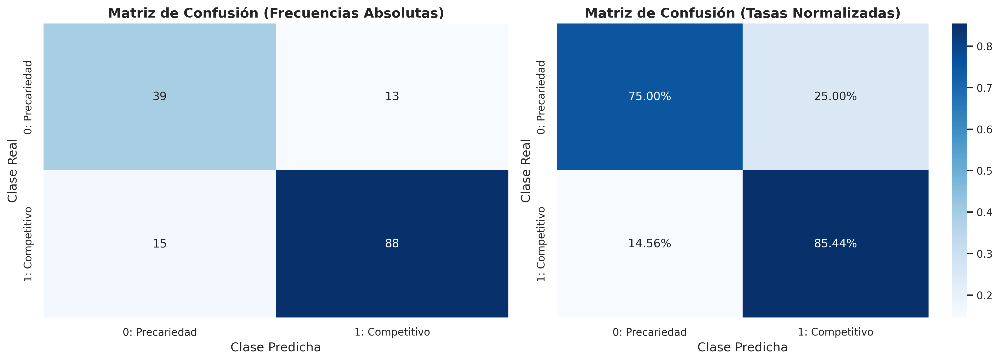

In [59]:
# ==============================================================================
# CELDA 13: VISUALIZACIÓN DE LA MATRIZ DE CONFUSIÓN
# ==============================================================================
import os

# Asegurar que el directorio de figuras existe para evitar FileNotFoundError
if not os.path.exists('figuras_modelado'):
    os.makedirs('figuras_modelado')

cm_abs = confusion_matrix(y_test, y_pred)
cm_norm = confusion_matrix(y_test, y_pred, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz Absoluta
sns.heatmap(
    cm_abs, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
    xticklabels=['0: Precariedad', '1: Competitivo'],
    yticklabels=['0: Precariedad', '1: Competitivo']
)
axes[0].set_title('Matriz de Confusión (Frecuencias Absolutas)', fontweight='bold')
axes[0].set_xlabel('Clase Predicha')
axes[0].set_ylabel('Clase Real')

# Matriz Normalizada
sns.heatmap(
    cm_norm, annot=True, fmt='.2%', cmap='Blues', cbar=True, ax=axes[1],
    xticklabels=['0: Precariedad', '1: Competitivo'],
    yticklabels=['0: Precariedad', '1: Competitivo']
)
axes[1].set_title('Matriz de Confusión (Tasas Normalizadas)', fontweight='bold')
axes[1].set_xlabel('Clase Predicha')
axes[1].set_ylabel('Clase Real')

plt.tight_layout()
plt.savefig('figuras_modelado/confusion_matrix.png', bbox_inches='tight')
plt.show()

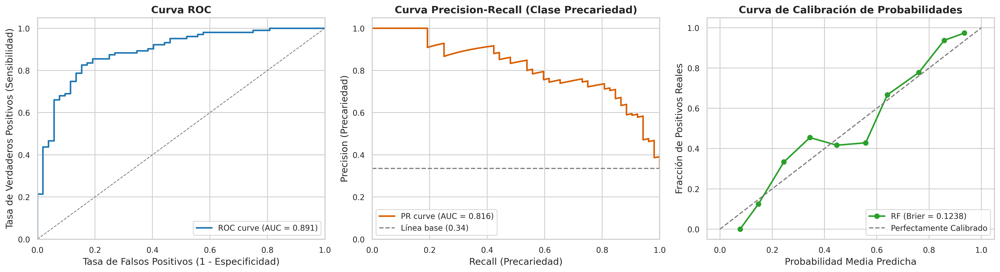

[DIAGNÓSTICO COMPLEMENTARIO] Out-of-Bag (OOB) Score: 0.8298
[DIAGNÓSTICO COMPLEMENTARIO] Brier Score Loss: 0.1238 (Valores cercanos a 0 indican óptima calibración)


In [60]:
# ==============================================================================
# CELDA 14: CURVAS ROC, PRECISION-RECALL, CALIBRACIÓN Y OOB SCORE
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Curva ROC
fpr, tpr, _ = roc_curve(y_test, proba_competitivo)
axes[0].plot(fpr, tpr, color='#1f77b4', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
axes[0].set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
axes[0].set_title('Curva ROC', fontweight='bold')
axes[0].legend(loc="lower right")

# 2. Curva Precision-Recall (focalizada en Precariedad: y == 0)
precision_c0, recall_c0, _ = precision_recall_curve(1 - y_test, proba_precariedad)
axes[1].plot(recall_c0, precision_c0, color='#d95f02', lw=2, label=f'PR curve (AUC = {pr_auc:.3f})')
axes[1].axhline(y=(y_test == 0).mean(), color='gray', linestyle='--', label=f'Línea base ({(y_test==0).mean():.2f})')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Recall (Precariedad)')
axes[1].set_ylabel('Precision (Precariedad)')
axes[1].set_title('Curva Precision-Recall (Clase Precariedad)', fontweight='bold')
axes[1].legend(loc="lower left")

# 3. Curva de Calibración
prob_true, prob_pred = calibration_curve(y_test, proba_competitivo, n_bins=10, strategy='uniform')
brier = brier_score_loss(y_test, proba_competitivo)
axes[2].plot(prob_pred, prob_true, marker='o', color='#2ca02c', lw=2, label=f'RF (Brier = {brier:.4f})')
axes[2].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectamente Calibrado')
axes[2].set_xlabel('Probabilidad Media Predicha')
axes[2].set_ylabel('Fracción de Positivos Reales')
axes[2].set_title('Curva de Calibración de Probabilidades', fontweight='bold')
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.savefig('figuras_modelado/diagnosticos_curvas.png', bbox_inches='tight')
plt.show()

# Evaluación de Out-Of-Bag (OOB) en un estimador análogo con oob_score=True
oob_params = best_pipeline.named_steps['classifier'].get_params()
oob_params['oob_score'] = True
oob_params['bootstrap'] = True
rf_oob = RandomForestClassifier(**oob_params)

# Ajuste sobre los datos de entrenamiento transformados
X_train_trans = best_pipeline.named_steps['preprocessor'].transform(X_train)
rf_oob.fit(X_train_trans, y_train)

print(f"[DIAGNÓSTICO COMPLEMENTARIO] Out-of-Bag (OOB) Score: {rf_oob.oob_score_:.4f}")
print(f"[DIAGNÓSTICO COMPLEMENTARIO] Brier Score Loss: {brier:.4f} (Valores cercanos a 0 indican óptima calibración)")

=== TABLA DE IMPORTANCIA DE VARIABLES CONCEPTUALES (RANDOM FOREST) ===


,Variable_Conceptual,Importancia,Ranking_RF
0,hrs_trabajo,0.225743,1
1,emp_formal_inf,0.188755,2
2,tipo_empresa,0.119749,3
3,edad,0.110714,4
4,tipo_empleado,0.084610,5
5,anios_estudio,0.081273,6
6,sexo,0.075087,7
7,edo_civil,0.064946,8
8,tiene_jefe,0.049125,9


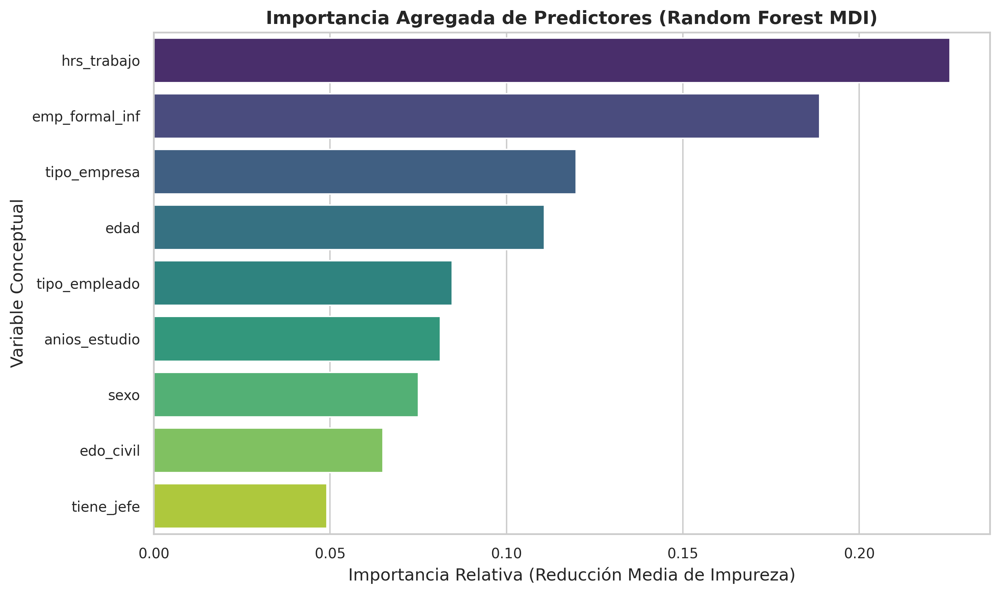

In [61]:
# ==============================================================================
# CELDA 15: IMPORTANCIA DE VARIABLES (GINI/IMPURITY) Y AGREGACIÓN CONCEPTUAL
# ==============================================================================

# Extracción de nombres de variables post-transformación
feature_names_transformed = best_pipeline.named_steps['preprocessor'].get_feature_names_out()
rf_estimator = best_pipeline.named_steps['classifier']
importances = rf_estimator.feature_importances_

# A. Tabla de Importancia a Nivel Transformado (Dummies individuales)
df_feat_imp_trans = pd.DataFrame({
    'Variable_Transformada': feature_names_transformed,
    'Importancia': importances
}).sort_values(by='Importancia', ascending=False).reset_index(drop=True)

# B. Agregación Conceptual por Variable Original
# La importancia de una variable categórica One-Hot es la suma de las importancias de sus categorías.
def mapear_variable_origen(feat_name, cat_list, num_list):
    for num in num_list:
        if feat_name.startswith(f"num__{num}"):
            return num
    for cat in cat_list:
        if feat_name.startswith(f"cat__{cat}"):
            return cat
    return feat_name

df_feat_imp_trans['Variable_Conceptual'] = df_feat_imp_trans['Variable_Transformada'].apply(
    lambda x: mapear_variable_origen(x, cat_features, num_features)
)

df_feat_imp_agrupada = df_feat_imp_trans.groupby('Variable_Conceptual')['Importancia'].sum().reset_index()
df_feat_imp_agrupada = df_feat_imp_agrupada.sort_values(by='Importancia', ascending=False).reset_index(drop=True)
df_feat_imp_agrupada['Ranking_RF'] = df_feat_imp_agrupada.index + 1

print("=== TABLA DE IMPORTANCIA DE VARIABLES CONCEPTUALES (RANDOM FOREST) ===")
display(df_feat_imp_agrupada)
df_feat_imp_agrupada.to_csv('resultados_modelado/feature_importance.csv', index=False)

# Visualización Gráfica
plt.figure(figsize=(10, 6))
sns.barplot(data=df_feat_imp_agrupada, x='Importancia', y='Variable_Conceptual', palette='viridis')
plt.title('Importancia Agregada de Predictores (Random Forest MDI)', fontweight='bold')
plt.xlabel('Importancia Relativa (Reducción Media de Impureza)')
plt.ylabel('Variable Conceptual')
plt.tight_layout()
plt.savefig('figuras_modelado/rf_feature_importance.png', bbox_inches='tight')
plt.show()

In [62]:
# ==============================================================================
# CELDA 16: PREPARACIÓN DE DATOS Y EXTRACCIÓN DE VALORES SHAP
# ==============================================================================

# 1. Transformar X_test usando el preprocesador ajustado en Train
X_test_transformed = best_pipeline.named_steps['preprocessor'].transform(X_test)
X_test_trans_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names_transformed,
    index=X_test.index
)

# 2. Instanciar SHAP TreeExplainer sobre el estimador entrenado
explainer = shap.TreeExplainer(rf_estimator)
shap_values_raw = explainer.shap_values(X_test_trans_df)

# 3. Detección adaptativa de estructura SHAP (Compatibilidad multi-versión)
# En clasificación binaria, determinamos los valores SHAP para la clase de interés.
# ORIENTACIÓN METODOLÓGICA: Explicaremos explícitamente la CLASE 0 (Precariedad).
# Un valor SHAP positivo indicará un incremento en la probabilidad/log-odds de Precariedad.
if isinstance(shap_values_raw, list):
    # Formato clásico lista de arrays [clase 0, clase 1]
    shap_precariedad = shap_values_raw[0]
    expected_val_precariedad = explainer.expected_value[0]
    shap_competitivo = shap_values_raw[1]
elif isinstance(shap_values_raw, np.ndarray) and len(shap_values_raw.shape) == 3:
    # Formato array 3D (n_samples, n_features, n_classes)
    shap_precariedad = shap_values_raw[:, :, 0]
    expected_val_precariedad = explainer.expected_value[0]
    shap_competitivo = shap_values_raw[:, :, 1]
else:
    # Salida directa unidimensional (asume clase positiva, invertimos para clase 0)
    shap_competitivo = shap_values_raw
    shap_precariedad = -shap_values_raw
    expected_val_precariedad = -explainer.expected_value if hasattr(explainer, 'expected_value') else 0

# Construcción de objeto Explanation formal para la clase Precariedad
shap_explanation_precariedad = shap.Explanation(
    values=shap_precariedad,
    base_values=np.repeat(expected_val_precariedad, len(X_test_trans_df)),
    data=X_test_trans_df.values,
    feature_names=feature_names_transformed
)

print("[OK] Valores SHAP calculados exitosamente.")
print(f"[ORIENTACIÓN ANALÍTICA] Explicación calibrada para CLASE 0: PRECARIEDAD.")
print(f"[VALOR BASE EXPECTED VALUE]: {expected_val_precariedad:.4f}")

[OK] Valores SHAP calculados exitosamente.
[ORIENTACIÓN ANALÍTICA] Explicación calibrada para CLASE 0: PRECARIEDAD.
[VALOR BASE EXPECTED VALUE]: 0.5002


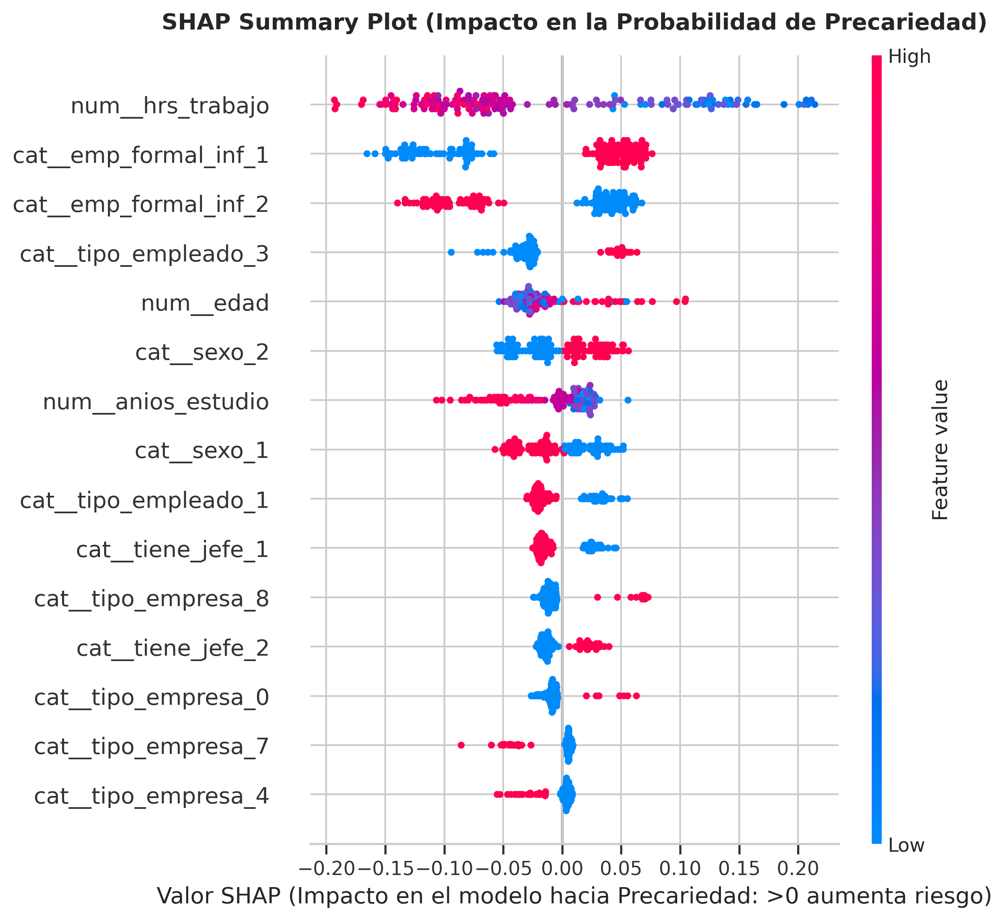

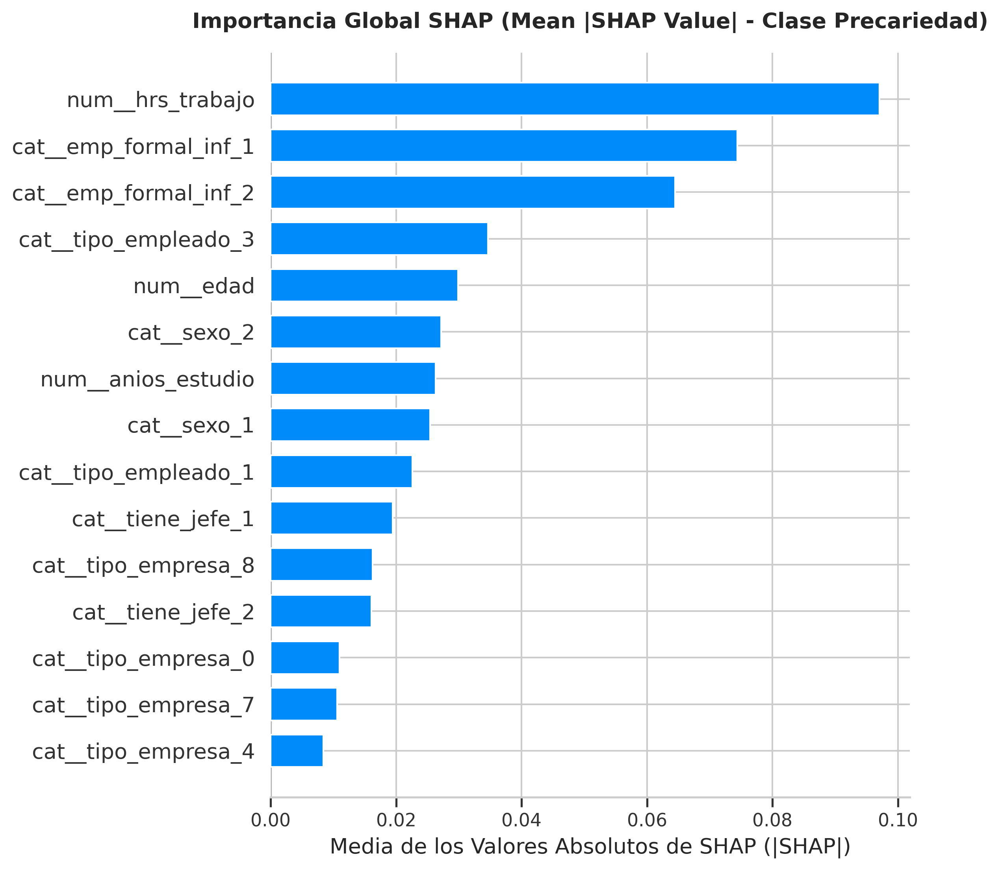

,Variable_Transformada,Mean_|SHAP|,Ranking_SHAP
0,num__hrs_trabajo,0.097054,1
1,cat__emp_formal_inf_1,0.074382,2
2,cat__emp_formal_inf_2,0.064452,3
3,cat__tipo_empleado_3,0.034657,4
4,num__edad,0.029891,5
5,cat__sexo_2,0.027168,6
6,num__anios_estudio,0.026289,7
7,cat__sexo_1,0.025455,8
8,cat__tipo_empleado_1,0.022621,9
9,cat__tiene_jefe_1,0.019446,10


In [63]:
# ==============================================================================
# CELDA 17: SHAP SUMMARY PLOT (BEESWARM) Y GLOBAL BAR PLOT
# ==============================================================================

# 1. Summary Plot (Beeswarm)
plt.figure(figsize=(11, 7))
shap.summary_plot(
    shap_precariedad,
    X_test_trans_df,
    feature_names=feature_names_transformed,
    max_display=15,
    show=False
)
plt.title('SHAP Summary Plot (Impacto en la Probabilidad de Precariedad)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Valor SHAP (Impacto en el modelo hacia Precariedad: >0 aumenta riesgo)')
plt.tight_layout()
plt.savefig('figuras_modelado/shap_summary.png', bbox_inches='tight')
plt.show()

# 2. Summary Bar Plot (Importancia Global Absoluta)
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_precariedad,
    X_test_trans_df,
    feature_names=feature_names_transformed,
    plot_type='bar',
    max_display=15,
    show=False
)
plt.title('Importancia Global SHAP (Mean |SHAP Value| - Clase Precariedad)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Media de los Valores Absolutos de SHAP (|SHAP|)')
plt.tight_layout()
plt.savefig('figuras_modelado/shap_bar.png', bbox_inches='tight')
plt.show()

# 3. Tabla de SHAP Global por Variable Transformada
mean_abs_shap = np.mean(np.abs(shap_precariedad), axis=0)
tabla_shap_global = pd.DataFrame({
    'Variable_Transformada': feature_names_transformed,
    'Mean_|SHAP|': mean_abs_shap
}).sort_values(by='Mean_|SHAP|', ascending=False).reset_index(drop=True)
tabla_shap_global['Ranking_SHAP'] = tabla_shap_global.index + 1

display(tabla_shap_global.head(15))
tabla_shap_global.to_csv('resultados_modelado/shap_global.csv', index=False)

=== TABLA DE IMPORTANCIA GLOBAL SHAP POR VARIABLE CONCEPTUAL ===


,Variable Conceptual,Mean Absolute SHAP Agregado,Ranking Conceptual
0,emp_formal_inf,0.138834,1
1,hrs_trabajo,0.097054,2
2,tipo_empleado,0.061208,3
3,tipo_empresa,0.058178,4
4,sexo,0.052624,5
5,tiene_jefe,0.035499,6
6,edad,0.029891,7
7,anios_estudio,0.026289,8
8,edo_civil,0.019792,9


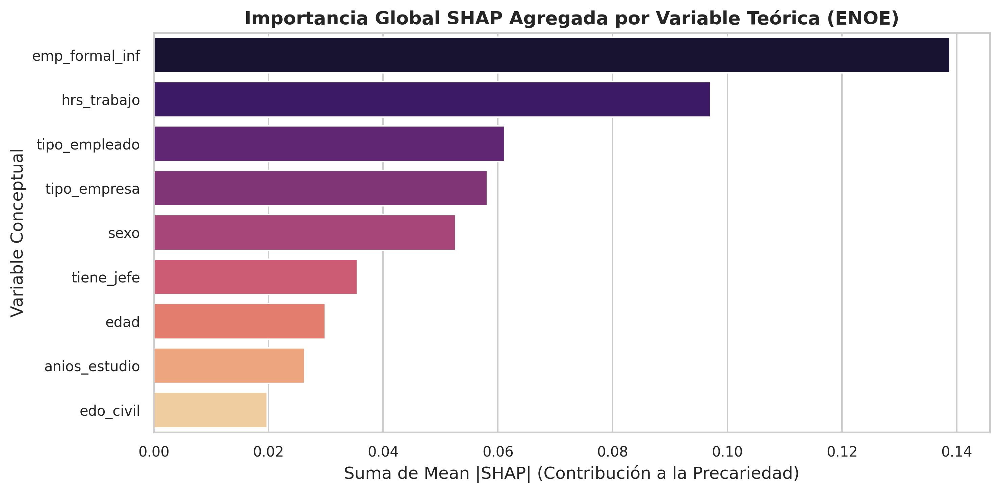

In [64]:
# ==============================================================================
# CELDA 18: AGREGACIÓN DE IMPACTO SHAP POR VARIABLE CONCEPTUAL ORIGINAL
# ==============================================================================

# Mapeo de variables transformadas a sus columnas conceptuales originales
tabla_shap_global['Variable_Conceptual'] = tabla_shap_global['Variable_Transformada'].apply(
    lambda x: mapear_variable_origen(x, cat_features, num_features)
)

# Metodología de agregación: Suma de la contribución absoluta media de todas las categorías One-Hot
tabla_shap_agrupada = tabla_shap_global.groupby('Variable_Conceptual')['Mean_|SHAP|'].sum().reset_index()
tabla_shap_agrupada = tabla_shap_agrupada.sort_values(by='Mean_|SHAP|', ascending=False).reset_index(drop=True)
tabla_shap_agrupada['Ranking_Conceptual'] = tabla_shap_agrupada.index + 1
tabla_shap_agrupada.columns = ['Variable Conceptual', 'Mean Absolute SHAP Agregado', 'Ranking Conceptual']

print("=== TABLA DE IMPORTANCIA GLOBAL SHAP POR VARIABLE CONCEPTUAL ===")
display(tabla_shap_agrupada)
tabla_shap_agrupada.to_csv('resultados_modelado/shap_agrupado.csv', index=False)

# Gráfico de barras horizontal conceptual
plt.figure(figsize=(10, 5))
sns.barplot(data=tabla_shap_agrupada, x='Mean Absolute SHAP Agregado', y='Variable Conceptual', palette='magma')
plt.title('Importancia Global SHAP Agregada por Variable Teórica (ENOE)', fontweight='bold')
plt.xlabel('Suma de Mean |SHAP| (Contribución a la Precariedad)')
plt.ylabel('Variable Conceptual')
plt.tight_layout()
plt.savefig('figuras_modelado/shap_conceptual_bar.png', bbox_inches='tight')
plt.show()

[INFO] Generando Dependence Plots para los 5 predictores clave: ['num__hrs_trabajo', 'cat__emp_formal_inf_1', 'cat__emp_formal_inf_2', 'cat__tipo_empleado_3', 'num__edad']


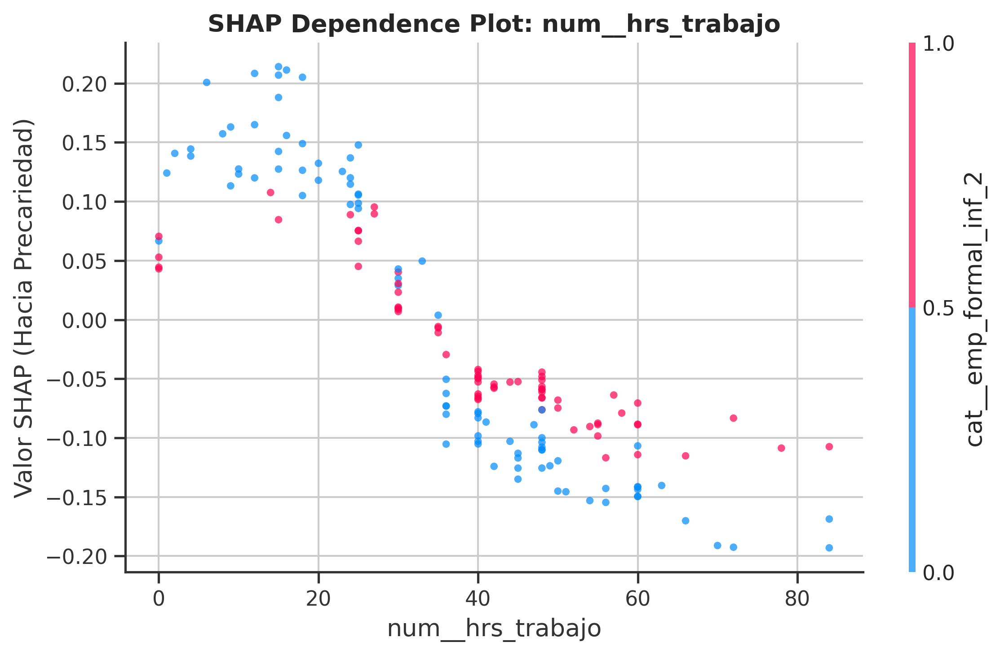

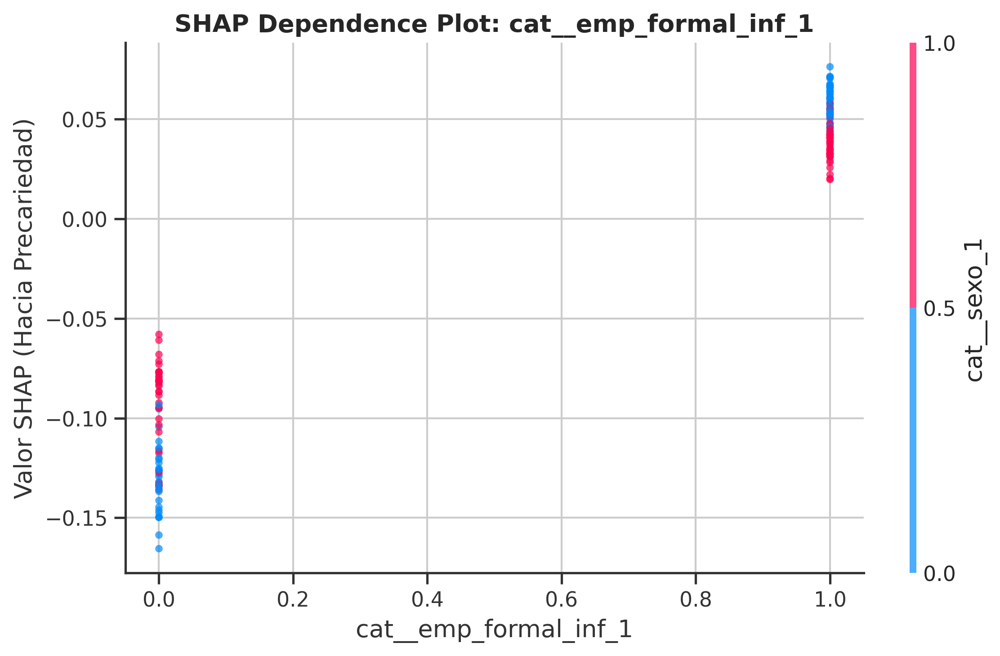

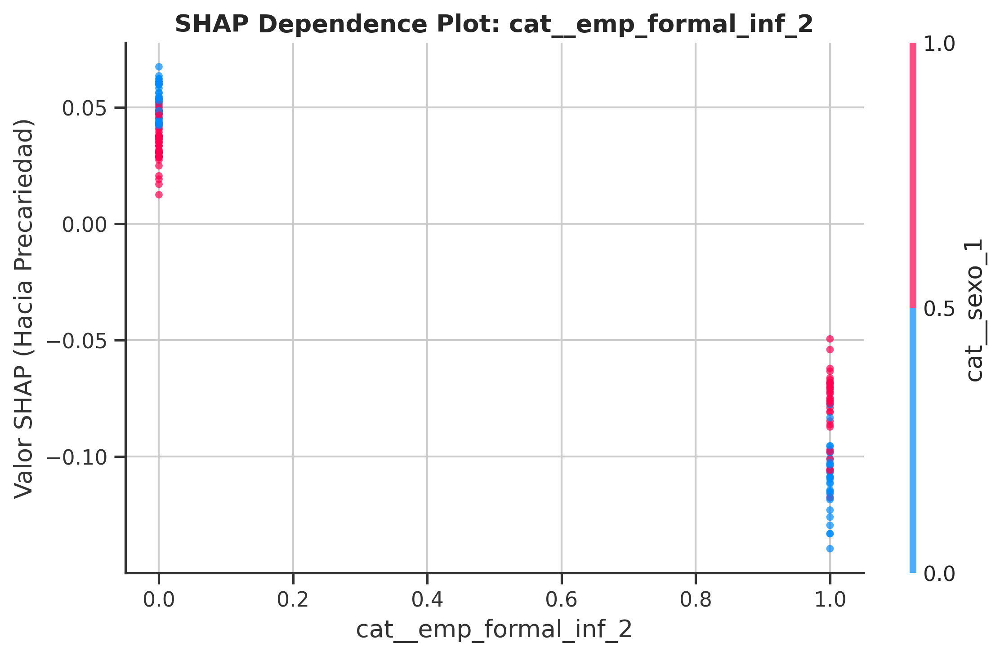

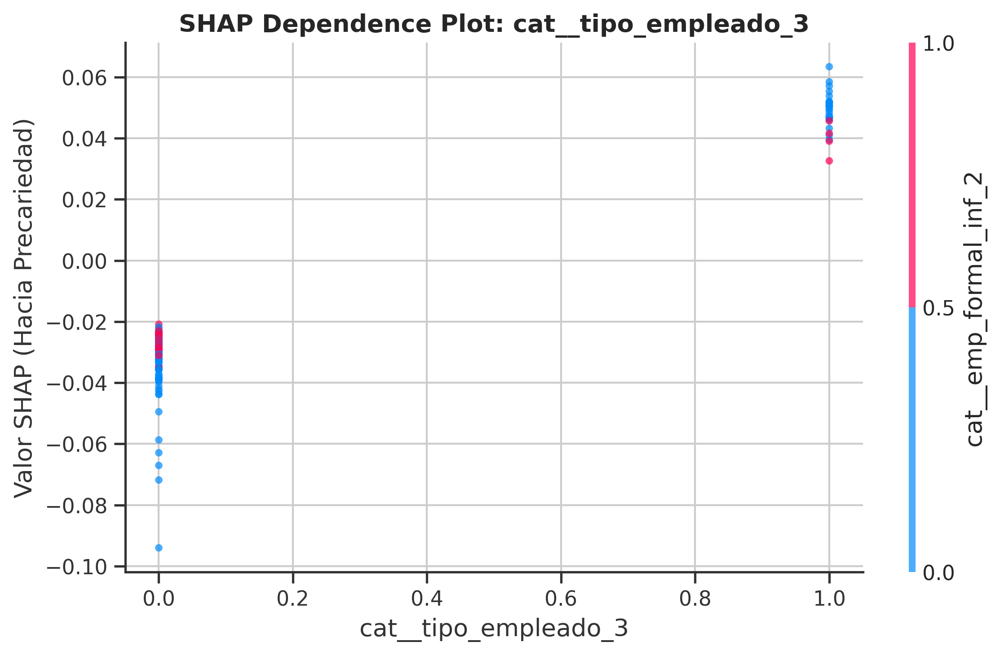

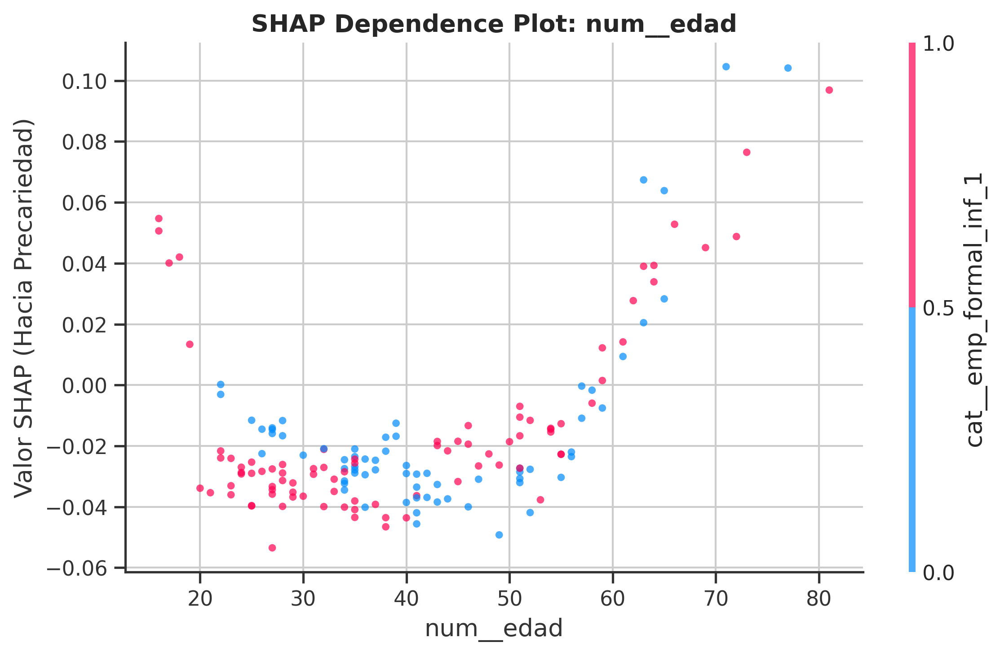

In [65]:
# ==============================================================================
# CELDA 19: SHAP DEPENDENCE PLOTS PARA LOS 5 PRINCIPALES PREDICTORES
# ==============================================================================

top_5_features_idx = np.argsort(mean_abs_shap)[::-1][:5]
top_5_features_names = [feature_names_transformed[i] for i in top_5_features_idx]

print(f"[INFO] Generando Dependence Plots para los 5 predictores clave: {top_5_features_names}")

for i, feat_name in enumerate(top_5_features_names):
    fig, ax = plt.subplots(figsize=(8, 5))
    shap.dependence_plot(
        feat_name,
        shap_precariedad,
        X_test_trans_df,
        feature_names=feature_names_transformed,
        show=False,
        ax=ax,
        alpha=0.7
    )
    ax.set_title(f'SHAP Dependence Plot: {feat_name}', fontweight='bold')
    ax.set_ylabel('Valor SHAP (Hacia Precariedad)')
    plt.tight_layout()
    # Limpieza de nombre de archivo para evitar errores de guardado
    safe_name = feat_name.replace('__', '_').replace('/', '_').replace(' ', '_')
    plt.savefig(f'figuras_modelado/shap_dependence_{i+1}_{safe_name}.png', bbox_inches='tight')
    plt.show()


CASO: Verdadero_Positivo_Precario (Índice Test: 4)
Clase Real: Precariedad (0) | Predicción: Precariedad (0)
Probabilidad Estimada de Precariedad: 0.6354


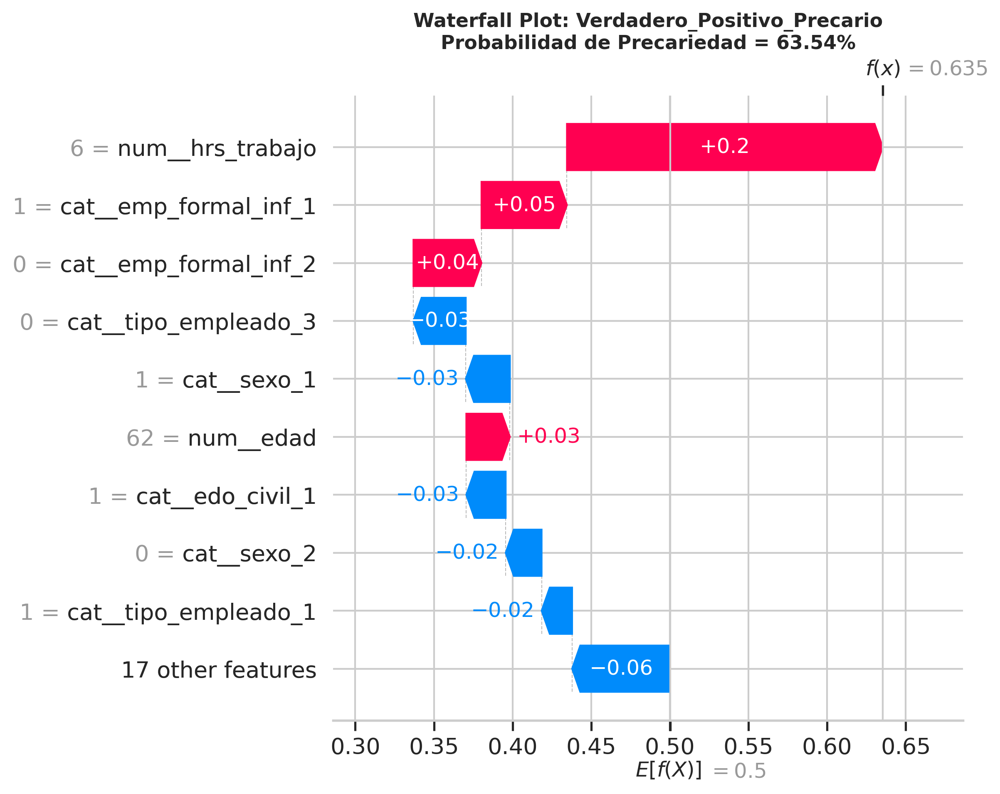


CASO: Verdadero_Negativo_Competitivo (Índice Test: 0)
Clase Real: Competitivo (1) | Predicción: Competitivo (1)
Probabilidad Estimada de Precariedad: 0.1673


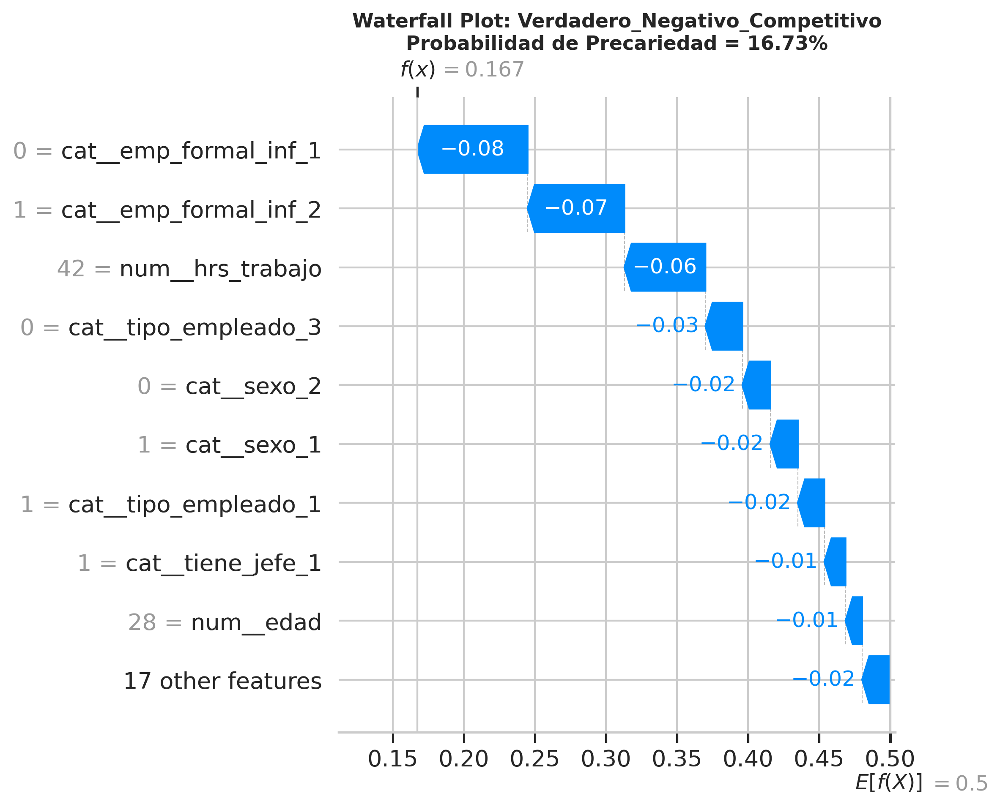


CASO: Falso_Positivo_PredichoPrecario_RealCompetitivo (Índice Test: 39)
Clase Real: Competitivo (1) | Predicción: Precariedad (0)
Probabilidad Estimada de Precariedad: 0.7720


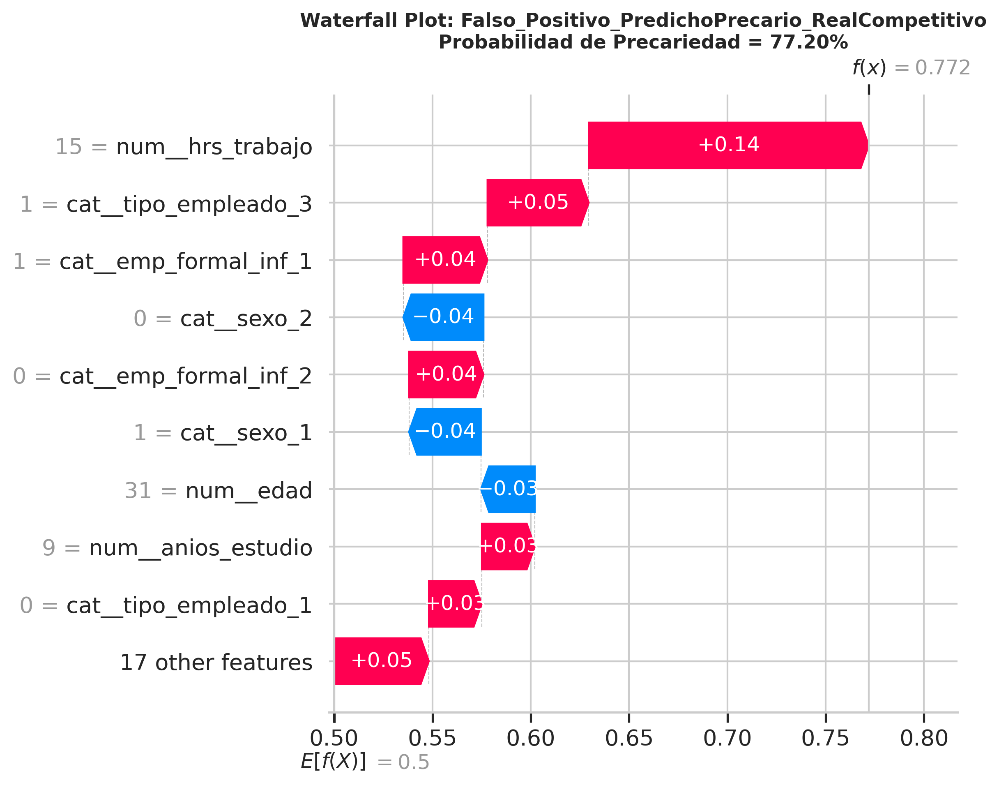


CASO: Falso_Negativo_PredichoCompetitivo_RealPrecario (Índice Test: 2)
Clase Real: Precariedad (0) | Predicción: Competitivo (1)
Probabilidad Estimada de Precariedad: 0.2134


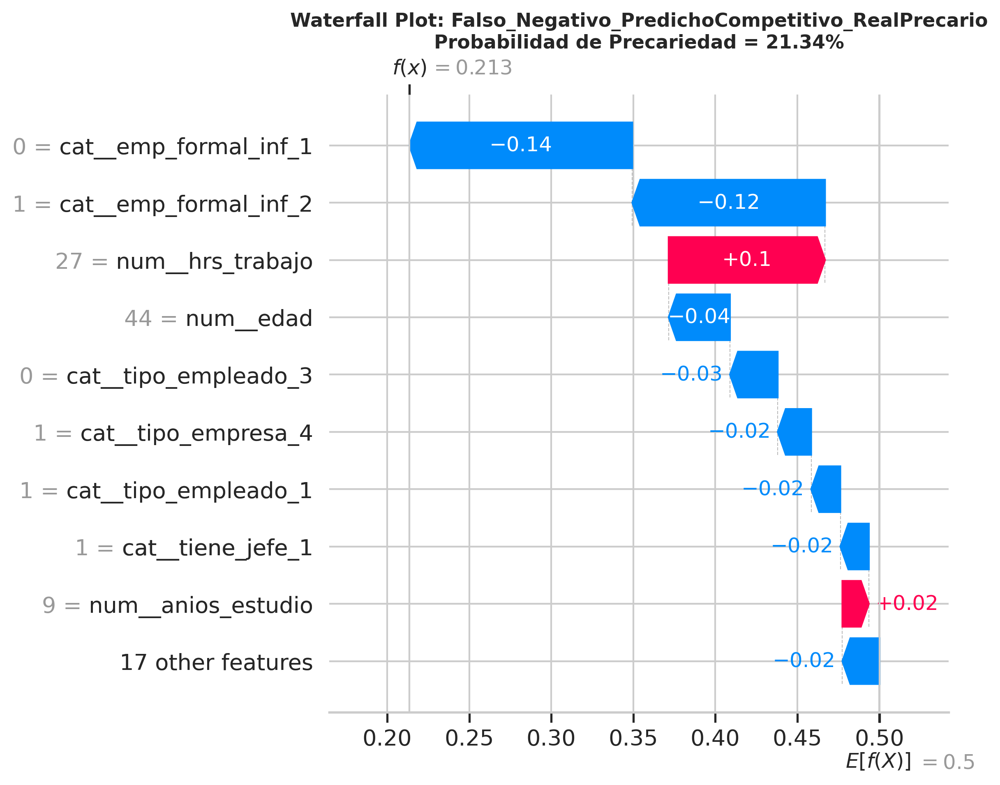

In [66]:
# ==============================================================================
# CELDA 20: EXPLICABILIDAD LOCAL (WATERFALL PLOTS) PARA 4 ARQUETIPOS
# ==============================================================================

# Identificación de índices para cada arquetipo en X_test
idx_tp = np.where((y_test.values == 0) & (y_pred == 0))[0]  # Verdadero Precario
idx_tn = np.where((y_test.values == 1) & (y_pred == 1))[0]  # Verdadero Competitivo
idx_fp = np.where((y_test.values == 1) & (y_pred == 0))[0]  # Falso Precario
idx_fn = np.where((y_test.values == 0) & (y_pred == 1))[0]  # Falso Competitivo

casos_seleccionados = {
    'Verdadero_Positivo_Precario': idx_tp[0] if len(idx_tp) > 0 else None,
    'Verdadero_Negativo_Competitivo': idx_tn[0] if len(idx_tn) > 0 else None,
    'Falso_Positivo_PredichoPrecario_RealCompetitivo': idx_fp[0] if len(idx_fp) > 0 else None,
    'Falso_Negativo_PredichoCompetitivo_RealPrecario': idx_fn[0] if len(idx_fn) > 0 else None
}

for etiqueta, idx_caso in casos_seleccionados.items():
    if idx_caso is not None:
        real_val = y_test.iloc[idx_caso]
        pred_val = y_pred[idx_caso]
        prob_prec = proba_precariedad[idx_caso]

        print(f"\n=======================================================")
        print(f"CASO: {etiqueta} (Índice Test: {idx_caso})")
        print(f"Clase Real: {MAPA_TARGET[real_val]} ({real_val}) | Predicción: {MAPA_TARGET[pred_val]} ({pred_val})")
        print(f"Probabilidad Estimada de Precariedad: {prob_prec:.4f}")
        print(f"=======================================================")

        plt.figure(figsize=(10, 6))
        shap.plots.waterfall(shap_explanation_precariedad[idx_caso], max_display=10, show=False)
        plt.title(f'Waterfall Plot: {etiqueta}\nProbabilidad de Precariedad = {prob_prec:.2%}', fontsize=11, fontweight='bold')
        plt.tight_layout()
        plt.savefig(f'figuras_modelado/shap_waterfall_{etiqueta}.png', bbox_inches='tight')
        plt.show()
    else:
        print(f"[AVISO] No se encontraron instancias para el arquetipo: {etiqueta}")

=== COMPARACIÓN DE IMPORTANCIA: RANDOM FOREST (MDI) VS. SHAP (GAME THEORY) ===


,Variable_Conceptual,Imp_RF_MDI,Ranking_RF,Imp_SHAP,Ranking Conceptual,Ranking_SHAP,Diferencia_Ranking (RF - SHAP)
0,emp_formal_inf,0.188755,2,0.138834,1,1,1
1,hrs_trabajo,0.225743,1,0.097054,2,2,-1
2,tipo_empleado,0.084610,5,0.061208,3,3,2
3,tipo_empresa,0.119749,3,0.058178,4,4,-1
4,sexo,0.075087,7,0.052624,5,5,2
5,tiene_jefe,0.049125,9,0.035499,6,6,3
6,edad,0.110714,4,0.029891,7,7,-3
7,anios_estudio,0.081273,6,0.026289,8,8,-2
8,edo_civil,0.064946,8,0.019792,9,9,-1


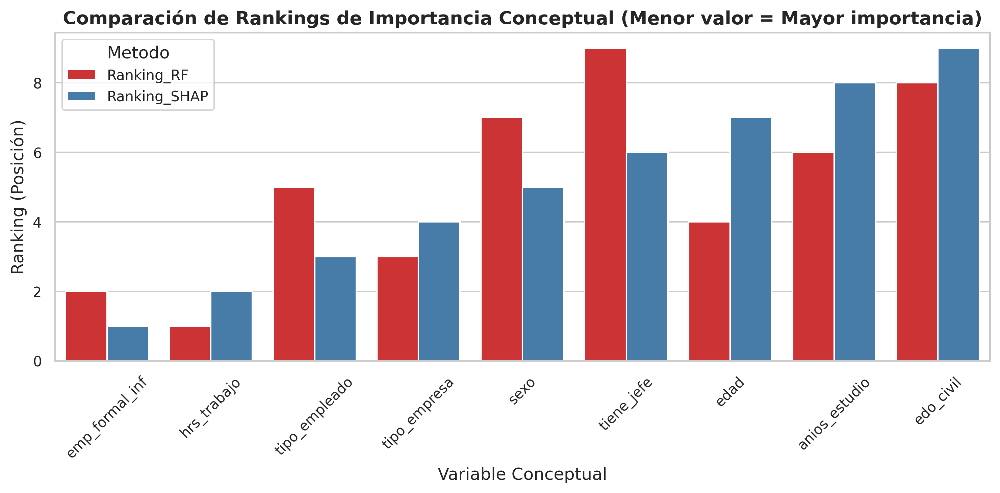

In [68]:
# ==============================================================================
# CELDA 21: TABLA COMPARATIVA DE IMPORTANCIAS Y DISCREPANCIAS METODOLÓGICAS
# ==============================================================================

# Cruce de importancias a nivel conceptual
tabla_comparacion_importancia = pd.merge(
    df_feat_imp_agrupada.rename(columns={'Importancia': 'Imp_RF_MDI'}),
    tabla_shap_agrupada.rename(columns={'Variable Conceptual': 'Variable_Conceptual', 'Mean Absolute SHAP Agregado': 'Imp_SHAP'}),
    on='Variable_Conceptual'
)

# Cálculo de rankings y discrepancia
tabla_comparacion_importancia['Ranking_RF'] = tabla_comparacion_importancia['Imp_RF_MDI'].rank(ascending=False).astype(int)
tabla_comparacion_importancia['Ranking_SHAP'] = tabla_comparacion_importancia['Imp_SHAP'].rank(ascending=False).astype(int)
tabla_comparacion_importancia['Diferencia_Ranking (RF - SHAP)'] = (
    tabla_comparacion_importancia['Ranking_RF'] - tabla_comparacion_importancia['Ranking_SHAP']
)

tabla_comparacion_importancia = tabla_comparacion_importancia.sort_values(by='Ranking_SHAP').reset_index(drop=True)

print("=== COMPARACIÓN DE IMPORTANCIA: RANDOM FOREST (MDI) VS. SHAP (GAME THEORY) ===")
display(tabla_comparacion_importancia)
tabla_comparacion_importancia.to_csv('resultados_modelado/comparacion_importancias.csv', index=False)

# Visualización comparativa de rankings
plt.figure(figsize=(10, 5))
df_plot_comp = tabla_comparacion_importancia.melt(
    id_vars=['Variable_Conceptual'],
    value_vars=['Ranking_RF', 'Ranking_SHAP'],
    var_name='Metodo', value_name='Ranking'
)
sns.barplot(data=df_plot_comp, x='Variable_Conceptual', y='Ranking', hue='Metodo', palette='Set1')
plt.title('Comparación de Rankings de Importancia Conceptual (Menor valor = Mayor importancia)', fontweight='bold')
plt.xlabel('Variable Conceptual')
plt.ylabel('Ranking (Posición)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('figuras_modelado/comparacion_rankings.png', bbox_inches='tight')
plt.show()

In [69]:
# ==============================================================================
# CELDA 22: EVALUACIÓN DE ROBUSTEZ MEDIANTE VALIDACIÓN CRUZADA REPETIDA
# ==============================================================================

# Validación formal de estabilidad estadística en 5 Folds sobre X_train
metricas_robustez = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'f1_macro': 'f1_macro',
    'roc_auc': 'roc_auc'
}

cv_eval = cross_validate(
    best_pipeline,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring=metricas_robustez,
    n_jobs=-1,
    return_train_score=False
)

tabla_robustez = pd.DataFrame({
    'Métrica Evaluada': ['Accuracy', 'Balanced Accuracy', 'F1-Score (Macro)', 'ROC-AUC'],
    'Media (CV)': [
        cv_eval['test_accuracy'].mean(),
        cv_eval['test_balanced_accuracy'].mean(),
        cv_eval['test_f1_macro'].mean(),
        cv_eval['test_roc_auc'].mean()
    ],
    'Desviación Estándar (CV)': [
        cv_eval['test_accuracy'].std(),
        cv_eval['test_balanced_accuracy'].std(),
        cv_eval['test_f1_macro'].std(),
        cv_eval['test_roc_auc'].std()
    ]
}).round(4)

print("=== EVALUACIÓN DE ROBUSTEZ Y ESTABILIDAD ESTADÍSTICA (5-FOLD CV) ===")
display(tabla_robustez)
tabla_robustez.to_csv('resultados_modelado/evaluacion_robustez.csv', index=False)

=== EVALUACIÓN DE ROBUSTEZ Y ESTABILIDAD ESTADÍSTICA (5-FOLD CV) ===


,Métrica Evaluada,Media (CV),Desviación Estándar (CV)
0,Accuracy,0.8136,0.0423
1,Balanced Accuracy,0.8004,0.0478
2,F1-Score (Macro),0.7941,0.0468
3,ROC-AUC,0.8759,0.0426


In [70]:
# ==============================================================================
# CELDA 23: SERIALIZACIÓN FINAL Y GENERACIÓN DE TABLA SÍNTESIS
# ==============================================================================

# 1. Serialización del Pipeline Completo
ruta_modelo_joblib = 'resultados_modelado/random_forest_final.joblib'
joblib.dump(best_pipeline, ruta_modelo_joblib)
print(f"[SERIALIZACIÓN] Pipeline completo guardado en: {ruta_modelo_joblib}")

# 2. Construcción de la Tabla Resumen para Tesis Doctoral
top_10_shap_names = tabla_shap_global.head(10)['Variable_Transformada'].tolist()

tabla_resultados_finales = pd.DataFrame({
    'Dimensión / Componente': [
        'Total Observaciones (Muestra)',
        'Observaciones en Entrenamiento (80%)',
        'Observaciones en Prueba (20%)',
        'Prevalencia Precariedad (Clase 0)',
        'Prevalencia Competitivo (Clase 1)',
        'Predictores Originales (X)',
        'Predictores Transformados (One-Hot)',
        'Número de Árboles (n_estimators)',
        'Profundidad Máxima (max_depth)',
        'Criterio de División',
        'Manejo de Desbalance (class_weight)',
        'ROC-AUC (Test Set)',
        'PR-AUC Precariedad (Test Set)',
        'Balanced Accuracy (Test Set)',
        'Accuracy Global (Test Set)',
        'F1-Score Precariedad (Test Set)',
        'Top 3 Variables Conceptuales (SHAP)'
    ],
    'Valor / Configuración': [
        len(df),
        len(X_train),
        len(X_test),
        f"{(y == 0).mean()*100:.2f}%",
        f"{(y == 1).mean()*100:.2f}%",
        len(num_features) + len(cat_features),
        len(feature_names_transformed),
        search.best_params_['classifier__n_estimators'],
        str(search.best_params_['classifier__max_depth']),
        search.best_params_['classifier__criterion'],
        str(search.best_params_['classifier__class_weight']),
        f"{roc_auc:.4f}",
        f"{pr_auc:.4f}",
        f"{bal_acc:.4f}",
        f"{acc:.4f}",
        f"{f1_precariedad:.4f}",
        ", ".join(tabla_shap_agrupada.head(3)['Variable Conceptual'].tolist())
    ]
})

print("\n=== TABLA SÍNTESIS FINAL PARA EL CAPÍTULO DE RESULTADOS ===")
display(tabla_resultados_finales)
tabla_resultados_finales.to_csv('resultados_modelado/tabla_resultados_finales.csv', index=False)

[SERIALIZACIÓN] Pipeline completo guardado en: resultados_modelado/random_forest_final.joblib

=== TABLA SÍNTESIS FINAL PARA EL CAPÍTULO DE RESULTADOS ===


,Dimensión / Componente,Valor / Configuración
0,Total Observaciones (Muestra),772
1,Observaciones en Entrenamiento (80%),617
2,Observaciones en Prueba (20%),155
3,Prevalencia Precariedad (Clase 0),33.29%
4,Prevalencia Competitivo (Clase 1),66.71%
5,Predictores Originales (X),9
6,Predictores Transformados (One-Hot),26
7,Número de Árboles (n_estimators),200
8,Profundidad Máxima (max_depth),8
9,Criterio de División,entropy
